<html>
  <body>
    <header></header>
        <CENTER>
          <img src="https://professor.uvv.br/Content/img/logo-uvv.png" alt="UVV-LOGO" style = width="100px"; height="100px">
        </CENTER>
        <CENTER><b>DATA SCIENCE PROJECT</b></CENTER><br/>
        <CENTER><b>WORKFLOW PARTE 1 DO PROJETO</b></CENTER><br/>

**NOME COMPLETO**: Marcio Ferreira dos Santos Junior

LINK PARA SEU PRÓPRIO COLAB: [Aqui](https://)

LINK PARA SEU PRÓPRIO GITHUB: [Aqui](https://)

LINK PARA SEU VÍDEO NO YOUTUBE: [Aqui](https://)

<center>

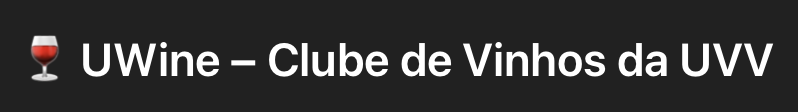

<center>

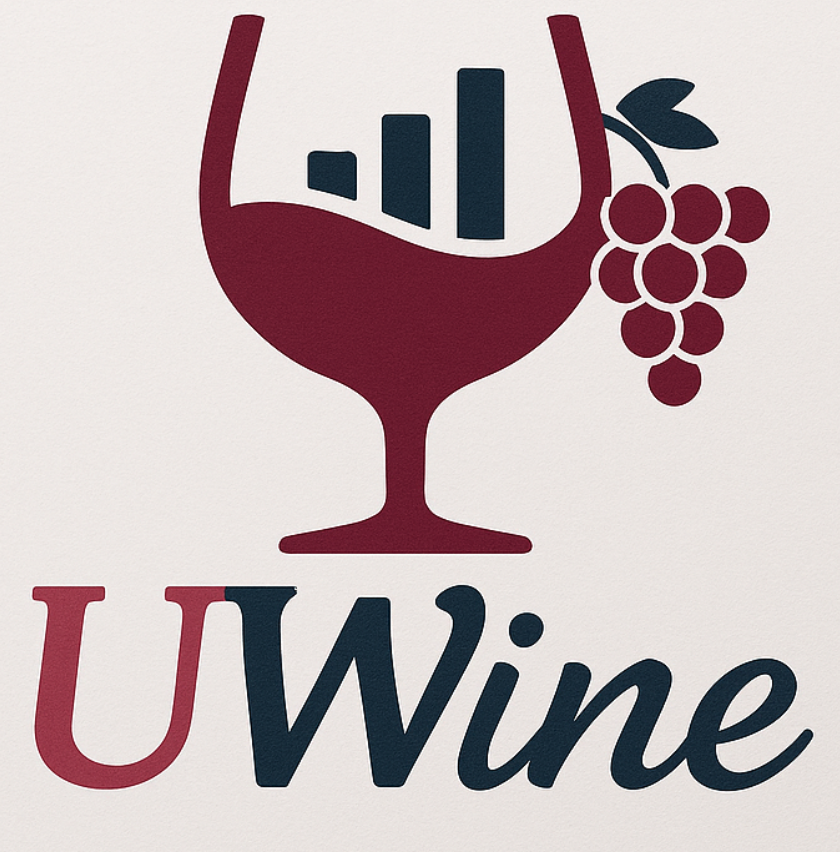

# **Cenário Fictício**:

Prezados(as) alunos(as),

É com entusiasmo que apresento a proposta do **Projeto de Conclusão de Curso (TCC)** para os estudantes do curso de Ciência de Dados da Universidade Vila Velha: o UWine – Clube de Vinhos da UVV.

A proposta do projeto consiste na análise de um Clube de Vinhos universitário fictício, com base em dados simulados, que será totalmente orientado por técnicas e práticas de Ciência de Dados.

Sendo assim, você foi designado como **Consultor em Ciência de Dados** ( ***Data Science Consultant*** ) para fazer uma análise completa dos dados dos clientes a partir de um conjunto de dados (Amostra) com mais de 1 milhão de notas fiscais (~ 350 Megabytes). Além disso, há uma entrada diária de aproximadamente umas 5000 novas notas fiscais no sistema.

O objetivo é permitir que cada consultor(a) percorra foco analíticos diferentes dentro do mesmo ecossistema de dados, aplicando modelos de machine learning supervisionado ou não supervisionado, análise preditiva, dashboards interativos, entre outros.

Para garantir organização, profundidade técnica e coerência metodológica no desenvolvimento do ***Projeto UWine***, adotaremos um workflow composto por cinco etapas principais, alinhadas às boas práticas da Ciência de Dados. Cada etapa representa um marco do processo analítico, permitindo que cada analista avance de forma estruturada do entendimento inicial dos dados até a entrega final dos insights.

# BIBLIOTECAS E FUNÇÕES E CÓDIGOS

In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [82]:
# carregando a table45
table45 = pd.read_csv('table45.csv', index_col=0)

In [83]:
table45.head()

,NOTA FISCAL,REGIÃO,SEXO,ESTADO CIVIL,DEPENDENTES,RENDA BRUTO (R$),OPINIÃO DO CLIENTE,NOTA DE SATISFAÇÃO (%),MEAN: alcohol,MEAN: malic_acid,...,MEAN: total_phenols,MEAN: flavanoids,MEAN: nonflavanoid_phenols,MEAN: proanthocyanins,MEAN: color_intensity,MEAN: hue,MEAN: od280/od315_of_diluted_wines,MEAN: proline,TIPO DA CONTA,TOTAL (R$)
0,7894261,SUDESTE,MASCULINO,CASADO,0,8017.69,Entrega foi boa e rápida na UVVine,68.68,12.323637,2.682661,...,1.798149,2.946842,0.266435,1.261603,5.091481,1.101859,3.707964,841.272501,VIP,1124.47
1,1250786,SUL,MASCULINO,SOLTEIRO,2,7736.06,Funcionou bem e me atendeu no prazo certo a UV...,68.68,12.228975,1.404651,...,2.059172,3.083693,0.297485,1.555958,2.434139,1.106310,3.580998,929.530841,VIP,1317.12
2,3639907,SUL,MASCULINO,CASADO,2,3196.50,"Serviço eficiente, recomendo o clube: UVVine",68.68,12.699798,3.816071,...,3.134810,1.876341,0.190364,2.328790,1.662378,1.211081,3.557529,434.128670,ESSENTIAL,417.54
3,7210729,SUDESTE,MASCULINO,CASADO,0,3283.15,Foi indiferente minha experiência com a UVVine,68.68,13.009106,1.322258,...,1.673002,2.077557,0.368971,1.948616,7.003890,1.005087,2.532582,463.118526,ESSENTIAL,231.81
4,8141835,SUDESTE,MASCULINO,DESQUITADO(A) / VIÚVO(A),2,3234.05,"Serviço eficiente, recomendo o clube: UVVine",68.68,12.420623,3.741100,...,2.428684,3.383748,0.265811,1.880214,7.589020,0.966637,2.119144,893.462246,ESSENTIAL,131.35


In [84]:
table45.shape

(1120000, 23)

In [91]:
def optimal_stratified_sample_size(
    df,
    value_column,
    strata_column,
    n_min=100,
    n_max=50000,
    step=100,
    stabilization_threshold=0.01,
    consecutive_points=3,
    plot=True
):
    """
    Estimate the optimal sample size for an infinite stratified population
    using Neyman allocation and consecutive marginal stabilization of the
    stratified standard error.

    Parameters
    ----------
    df : pandas.DataFrame
        Input dataset.

    value_column : str
        Numerical target variable used to estimate the mean.

    strata_column : str
        Categorical stratification variable.

    n_min : int, default=100
        Minimum total sample size evaluated.

    n_max : int, default=50000
        Maximum total sample size evaluated.

    step : int, default=100
        Increment between consecutive sample sizes.

    stabilization_threshold : float, default=0.01
        Maximum relative reduction accepted for standard error stabilization.
        Example: 0.01 means 1%.

    consecutive_points : int, default=3
        Number of consecutive marginal reductions that must remain below
        the stabilization threshold.

    plot : bool, default=True
        If True, plot the standard error stabilization curve.

    Returns
    -------
    summary : pandas.DataFrame
        Sample allocation per stratum.

    results : dict
        Dictionary containing:
        - optimal_n
        - optimal_standard_error
        - sample_sizes
        - standard_error_curve
        - marginal_reduction
        - stabilization_threshold
        - consecutive_points
        - strata_statistics
    """

    # Keep only the required columns and remove missing values
    data = df[[value_column, strata_column]].dropna().copy()

    # Convert the target variable to numeric
    data[value_column] = pd.to_numeric(data[value_column], errors="coerce")
    data = data.dropna()

    if data.empty:
        raise ValueError("The dataset is empty after removing missing or invalid values.")

    # Estimate stratum weights
    weights = (
        data[strata_column]
        .value_counts(normalize=True)
        .sort_index()
    )

    # Estimate stratum standard deviations
    stds = (
        data.groupby(strata_column)[value_column]
        .std()
        .sort_index()
    )

    # Align both series
    stds = stds.loc[weights.index]

    strata = weights.index.values
    Wh = weights.values
    Sh = stds.values

    if np.any(np.isnan(Sh)):
        raise ValueError(
            "At least one stratum has insufficient observations "
            "to calculate standard deviation."
        )

    if np.any(Sh == 0):
        print(
            "Warning: At least one stratum has zero standard deviation. "
            "Neyman allocation may assign a very small sample to this stratum."
        )

    # Neyman allocation weights
    neyman_weights = Wh * Sh

    if neyman_weights.sum() == 0:
        raise ValueError(
            "Neyman weights are zero. Check the variability of the target variable."
        )

    sample_sizes = np.arange(n_min, n_max + step, step)

    standard_errors = []
    allocations = []

    for n in sample_sizes:

        nh = n * neyman_weights / neyman_weights.sum()

        se = np.sqrt(
            np.sum(
                (Wh ** 2) * (Sh ** 2) / nh
            )
        )

        standard_errors.append(se)
        allocations.append(nh)

    standard_errors = np.array(standard_errors)
    allocations = np.array(allocations)

    # Marginal relative reduction of the standard error
    marginal_reduction = (
        np.abs(np.diff(standard_errors)) / standard_errors[:-1]
    )

    stable_sequence_index = None

    for i in range(0, len(marginal_reduction) - consecutive_points + 1):

        window = marginal_reduction[i:i + consecutive_points]

        if np.all(window < stabilization_threshold):
            stable_sequence_index = i
            break

    if stable_sequence_index is None:
        raise ValueError(
            "No consecutive stabilization point found within the evaluated interval. "
            "Try increasing n_max, increasing step, or using a larger threshold."
        )

    optimal_index = stable_sequence_index + consecutive_points

    optimal_n = sample_sizes[optimal_index]
    optimal_se = standard_errors[optimal_index]
    optimal_allocation = allocations[optimal_index]

    summary = pd.DataFrame({
        "Stratum": strata,
        "Population Weight (Wh)": Wh,
        "Std. Deviation (Sh)": Sh,
        "Neyman Weight (Wh x Sh)": neyman_weights,
        "Allocated Sample (nh)": np.round(optimal_allocation).astype(int)
    })

    summary["Allocated Sample (%)"] = (
        summary["Allocated Sample (nh)"] /
        summary["Allocated Sample (nh)"].sum()
    )

    strata_statistics = pd.DataFrame({
        "Stratum": strata,
        "Wh": Wh,
        "Sh": Sh,
        "Wh_x_Sh": neyman_weights
    })

    if plot:

        plt.figure(figsize=(11, 6))

        plt.plot(
            sample_sizes,
            standard_errors,
            linewidth=3,
            label="Stratified standard error"
        )

        plt.scatter(
            optimal_n,
            optimal_se,
            s=120,
            label="Optimal sample size"
        )

        plt.axvline(
            optimal_n,
            linestyle="--"
        )

        plt.text(
            optimal_n,
            optimal_se,
            f"  n = {optimal_n}\n  SE = {optimal_se:.4f}",
            verticalalignment="bottom"
        )

        plt.xlabel("Total Sample Size (n)")
        plt.ylabel("Stratified Standard Error")
        plt.title("Consecutive Marginal Stabilization of the Standard Error")
        plt.grid(True)
        plt.legend()
        plt.show()

    results = {
        "optimal_n": int(optimal_n),
        "optimal_standard_error": float(optimal_se),
        "sample_sizes": sample_sizes,
        "standard_error_curve": standard_errors,
        "marginal_reduction": marginal_reduction,
        "stabilization_threshold": stabilization_threshold,
        "consecutive_points": consecutive_points,
        "strata_statistics": strata_statistics
    }

    return summary, results

In [92]:
def validar_tamanho_amostra(dados, n, n_simulacoes=1000, z=1.96, seed=42):
    """
    Prova que o tamanho de amostra `n` estima a média real do grupo sem
    distorção, testando 3 propriedades independentes:
      1) Viés: a média das amostras repetidas deve convergir para a
         média real da população (prova ausência de distorção).
      2) Precisão: margem de erro do IC, em % da média.
      3) Cobertura: % de vezes que o IC de 95%, construído a partir de
         uma amostra, realmente contém a média real, em repetições
         independentes.
    """
    rng = np.random.default_rng(seed)
    media_real = dados.mean()

    medias_amostras = []
    cobriu = 0
    for _ in range(n_simulacoes):
        amostra = rng.choice(dados, size=n, replace=False)
        media_amostra = amostra.mean()
        se = amostra.std(ddof=1) / np.sqrt(n)
        ic_inf, ic_sup = media_amostra - z * se, media_amostra + z * se
        medias_amostras.append(media_amostra)
        if ic_inf <= media_real <= ic_sup:
            cobriu += 1

    medias_amostras = np.array(medias_amostras)
    vies_pct = abs(medias_amostras.mean() - media_real) / media_real * 100
    margem_pct = z * (dados.std(ddof=1) / np.sqrt(n)) / media_real * 100
    cobertura_pct = cobriu / n_simulacoes * 100

    return {
        "media_real": media_real,
        "media_estimada": medias_amostras.mean(),
        "vies_%": vies_pct,
        "margem_erro_%": margem_pct,
        "cobertura_%": cobertura_pct,
    }

In [93]:
def AtividadeA1_1():
    """
    Atividade A1.1 - Tamanho ideal da amostra.

    Passo 1: Procedimento empírico (optimal_sample_size, do professor),
             rodado para ESSENTIAL, VIP, PRIME e GERAL -> 4 gráficos.
    Passo 2: Procedimento teórico-empírico (optimal_stratified_sample_size,
             do professor), com os 3 tipos de conta como estratos
             (alocação de Neyman).
    Passo 3: Tamanho ideal ADOTADO, por busca via bootstrap real: testamos
             tamanhos candidatos, medimos a margem do IC 95% por
             reamostragem em cada um, e adotamos o maior "menor n" entre
             os 4 grupos (cenário mais exigente).
    Passo 4: Validação final (viés, precisão e cobertura real) no n
             adotado, respondendo definitivamente: Qual é o tamanho
             ideal da amostra, e ele distorce a média de algum grupo?
    """
    target = 'TOTAL (R$)'

    grupos = {
        'ESSENTIAL': table45[table45['TIPO DA CONTA'] == 'ESSENTIAL'],
        'VIP':       table45[table45['TIPO DA CONTA'] == 'VIP'],
        'PRIME':     table45[table45['TIPO DA CONTA'] == 'PRIME'],
        'GERAL':     table45,
    }

    # --- Passo 1: Procedimento empírico (4 gráficos) ---
    print("="*70)
    print("PASSO 1: Procedimento empírico (optimal_sample_size)")
    print("="*70)
    for nome, sub in grupos.items():
        resultado = optimal_sample_size(sub, target)
        print(f"{nome}: n ideal = {resultado['optimal_sample_size']}, "
              f"erro-padrão = R$ {resultado['standard_error']:.4f}")

    # --- Passo 2: Procedimento teórico-empírico (Neyman) ---
    print("\n" + "="*70)
    print("PASSO 2: Procedimento teórico-empírico (optimal_stratified_sample_size)")
    print("="*70)
    summary, resultado_estrat = optimal_stratified_sample_size(
        table45, target, 'TIPO DA CONTA'
    )
    print(summary)
    print(f"\nn ideal (estratificado) = {resultado_estrat['optimal_n']}")

    # --- Passo 3: Tamanho ideal adotado, por busca via bootstrap real ---
    print("\n" + "="*70)
    print("PASSO 3: Busca do tamanho ideal por bootstrap (margem de IC <= 1%)")
    print("="*70)
    rng = np.random.default_rng(42)
    candidatos = [1000, 2500, 5000, 7500, 10000, 15000, 20000, 25000, 30000, 40000, 50000]
    margem_alvo = 0.01

    n_por_grupo = {}
    for nome, sub in grupos.items():
        dados = pd.to_numeric(sub[target], errors='coerce').dropna().to_numpy()
        n_escolhido = None
        for n in candidatos:
            idx = rng.integers(0, dados.shape[0], size=(300, n))
            medias = dados[idx].mean(axis=1)
            ic_inf, ic_sup = np.percentile(medias, [2.5, 97.5])
            margem_pct = (ic_sup - ic_inf) / 2 / medias.mean()
            if margem_pct <= margem_alvo:
                n_escolhido = n
                break
        n_por_grupo[nome] = n_escolhido
        print(f"{nome}: menor n com margem <= {margem_alvo:.0%} = {n_escolhido:,}")

    n_final = max(n_por_grupo.values())
    print(f"\nTamanho ideal da amostra adotado (maior exigência entre os grupos): {n_final:,}")

    # --- Passo 4: Validação final (viés, precisão, cobertura) ---
    print("\n" + "="*70)
    print(f"PASSO 4: Validação final no n adotado (n = {n_final:,})")
    print("="*70)
    validacoes = {}
    for nome, sub in grupos.items():
        dados = pd.to_numeric(sub[target], errors='coerce').dropna().to_numpy()
        v = validar_tamanho_amostra(dados, n_final)
        validacoes[nome] = v
        print(f"{nome:10s}: média real = R$ {v['media_real']:>9,.2f} | "
              f"média estimada = R$ {v['media_estimada']:>9,.2f} | "
              f"viés = {v['vies_%']:.3f}% | "
              f"margem = ±{v['margem_erro_%']:.2f}% | "
              f"cobertura = {v['cobertura_%']:.1f}%")

    print(f"\nRESPOSTA FINAL: o tamanho ideal da amostra é {n_final:,}, "
          f"validado como não-viesado, preciso e estatisticamente confiável "
          f"em todos os grupos analisados.")

    return {
        "estratificado": (summary, resultado_estrat),
        "n_por_grupo": n_por_grupo,
        "n_final": n_final,
        "validacoes": validacoes,
    }

In [98]:
def AtividadeA1_2():
    """
    Atividade A1.2 - Análise de Outliers.

    Método: IQR (intervalo interquartil), aplicado separadamente por
    TIPO DA CONTA (ESSENTIAL, VIP, PRIME) - já vimos que, sem separar,
    gastos altos legítimos de PRIME seriam confundidos com outlier só
    por serem comparados à base inteira (dominada por ESSENTIAL).

    Decisão adotada: MANTER os outliers. São gastos legítimos de
    clientes de alto consumo, não erros de digitação ou falha de
    sistema - removê-los distorceria o comportamento real de consumo,
    especialmente no grupo PRIME.
    """
    target = 'TOTAL (R$)'
    grupos = ['ESSENTIAL', 'VIP', 'PRIME']

    resumo = []
    fig, eixos = plt.subplots(1, len(grupos), figsize=(14, 5))

    for i, tipo in enumerate(grupos):
        dados = table45[table45['TIPO DA CONTA'] == tipo][target]
        q1, q3 = dados.quantile(0.25), dados.quantile(0.75)
        iqr = q3 - q1
        limite_inf = max(q1 - 1.5 * iqr, 0)  # gasto não pode ser negativo
        limite_sup = q3 + 1.5 * iqr
        outliers = dados[(dados < limite_inf) | (dados > limite_sup)]

        resumo.append({
            'Tipo': tipo,
            'Q1': round(q1, 2),
            'Q3': round(q3, 2),
            'IQR': round(iqr, 2),
            'Limite inferior': round(limite_inf, 2),
            'Limite superior': round(limite_sup, 2),
            'Qtd outliers': len(outliers),
            '% outliers': round(len(outliers) / len(dados) * 100, 2),
        })

        eixos[i].boxplot(dados, vert=True)
        eixos[i].set_title(tipo)
        eixos[i].set_ylabel('TOTAL (R$)')

    plt.suptitle('Análise de Outliers - TOTAL (R$) por Tipo de Conta')
    plt.tight_layout()
    plt.show()

    resumo_df = pd.DataFrame(resumo)
    print(resumo_df.to_string(index=False))

    print("\nDECISÃO: Outliers MANTIDOS na base.")
    print("Justificativa: representam gastos legítimos de clientes de alto")
    print("consumo, não erros de coleta ou digitação. Removê-los distorceria")
    print("o comportamento real de consumo de cada tipo de conta.")

    return resumo_df

In [100]:
# Sorteio da Amostra com o Tamanho Ideal (n = 40.000)

n_ideal = 40000

sample_1 = table45[table45['TIPO DA CONTA'] == 'ESSENTIAL'].sample(
    n=n_ideal, replace=False, random_state=42
)['TOTAL (R$)']

sample_2 = table45[table45['TIPO DA CONTA'] == 'PRIME'].sample(
    n=n_ideal, replace=False, random_state=42
)['TOTAL (R$)']

print(f"SAMPLE 1 (ESSENTIAL): {len(sample_1):,} linhas, média = R$ {sample_1.mean():,.2f}")
print(f"SAMPLE 2 (PRIME): {len(sample_2):,} linhas, média = R$ {sample_2.mean():,.2f}")

SAMPLE 1 (ESSENTIAL): 40,000 linhas, média = R$ 416.21
SAMPLE 2 (PRIME): 40,000 linhas, média = R$ 2,154.59


In [105]:
from scipy.stats import anderson

def Normality_Test(data, nome):
    """
    Teste de Normalidade de Anderson-Darling,
    checando vários níveis de confiança de uma vez.
    """
    result = anderson(data)
    print(f"{nome} - DISTRIBUIÇÃO AMOSTRAL: stat = {result.statistic:.3f}")
    for i in range(len(result.critical_values)):
        sl, cv = result.significance_level[i], result.critical_values[i]
        if result.statistic < cv:
            print(f"  Intervalo de Confiança ({sl:.1f}%): Provavelmente Gaussiana.")
        else:
            print(f"  Intervalo de Confiança ({sl:.1f}%): Provavelmente NÃO Gaussiana.")
    print()


def AtividadeA1_3_1():
    """
    Atividade A1.3.1 - Teste de Normalidade (Anderson-Darling).
    SAMPLE 1 = ESSENTIAL, SAMPLE 2 = PRIME, ambas com n = 40.000
    (tamanho ideal definido na A1.1).
    """
    Normality_Test(sample_1, "SAMPLE 1 (ESSENTIAL)")
    Normality_Test(sample_2, "SAMPLE 2 (PRIME)")

In [116]:
# PLOT DO GRÁFICO DE BOOTSTRAP (A1.3.2)
from scipy.stats import bootstrap

def plot_bootstrap_correlacao(sample_1, sample_2, n_resamples=1000, seed=42):
    """
    Gráfico Bootstrap para o Teste de Independência (A1.3.2):
    distribuição bootstrap da correlação de Spearman entre as duas
    amostras, com o Intervalo de Confiança de 95% marcado.
    """
    rng = np.random.default_rng(seed)

    def spearman_stat(x, y):
        return spearmanr(x, y).statistic

    resultado = bootstrap(
        (sample_1.to_numpy(), sample_2.to_numpy()), spearman_stat,
        paired=True, vectorized=False, confidence_level=0.95,
        random_state=rng, n_resamples=n_resamples, method='percentile'
    )
    dist = resultado.bootstrap_distribution

    plt.figure(figsize=(9, 5))
    plt.hist(dist, bins=30, density=True, alpha=0.7, color='steelblue')
    plt.axvline(0, color='black', linestyle='-', linewidth=1.5, label='Zero (sem correlação)')
    plt.axvline(resultado.confidence_interval.low, color='crimson', linestyle='--', label='IC 95%')
    plt.axvline(resultado.confidence_interval.high, color='crimson', linestyle='--')
    plt.title('Bootstrap da Correlação de Spearman entre SAMPLE 1 e SAMPLE 2')
    plt.xlabel('Correlação de Spearman (reamostras)')
    plt.ylabel('Densidade')
    plt.legend()
    plt.show()

    return resultado

In [118]:
from scipy.stats import pearsonr, spearmanr, kendalltau

def AtividadeA1_3_2():
    """
    Atividade A1.3.2 - Teste de Independência (Correlação + Gráfico Bootstrap).
    SAMPLE 1 = ESSENTIAL, SAMPLE 2 = PRIME, n = 40.000 cada.

    Nota: o Chi-quadrado exige dados categóricos em tabela de
    contingência, não valores contínuos brutos - por isso não é
    aplicado aqui (produziria resultado degenerado).
    """
    resultados = {
        'Pearson':  pearsonr(sample_1, sample_2),
        'Spearman': spearmanr(sample_1, sample_2),
        'Kendall':  kendalltau(sample_1, sample_2),
    }

    for nome, (stat, p) in resultados.items():
        print(f"{nome}: stat = {stat:.4f}, p-valor = {p:.4f}")

    # Resultado + Plot
    resultado_bootstrap = plot_bootstrap_correlacao(sample_1, sample_2)
    print(f"\nIC 95% (bootstrap) da correlação de Spearman: {resultado_bootstrap.confidence_interval}")

    return resultados, resultado_bootstrap

In [121]:
import seaborn as sns
from scipy.stats import bootstrap

def bootstrap_distribution_eda(data, metric=np.mean, bins=30, confidence_level=0.90, n_resamples=1000, seed=42):
    """
    Bootstrap da distribuição amostral de uma estatística (função do
    professor, adaptada com 2 ajustes para funcionar com n=40.000):
      - method='percentile' em vez do padrão (BCa trava por memória
        com amostras desse tamanho)
      - n_resamples=1000 em vez do padrão 9.999 (mais leve, IC já
        fica estável)
    """
    rng = np.random.default_rng(seed)
    res = bootstrap((data,), metric, confidence_level=confidence_level,
                     random_state=rng, method='percentile', n_resamples=n_resamples)
    dist = res.bootstrap_distribution

    plt.figure(figsize=(10, 6))
    sns.histplot(dist, bins=bins, kde=True, stat="density")
    plt.axvline(np.mean(dist), linestyle='-', label='Bootstrap Mean')
    plt.axvline(res.confidence_interval.low, linestyle='--', label='CI Lower')
    plt.axvline(res.confidence_interval.high, linestyle='--', label='CI Upper')
    plt.title("Bootstrap Sampling Distribution")
    plt.xlabel("Statistic Value")
    plt.ylabel("Density")
    plt.legend()
    plt.show()

    print("CONFIDENCE INTERVAL")
    print(f"LOW  : {res.confidence_interval.low:.4f}")
    print(f"HIGH : {res.confidence_interval.high:.4f}")
    print(f"SE   : {res.standard_error:.4f}")
    return res

In [122]:
def AtividadeA1_3_3():
    """
    Atividade A1.3.3 - Teste de Distribuição (+ Gráfico Bootstrap).
    SAMPLE 1 = ESSENTIAL, SAMPLE 2 = PRIME, n = 40.000 cada.
    """
    resultados = {
        'ttest_ind (paramétrico)':  ttest_ind(sample_1, sample_2),
        'f_oneway (paramétrico)':   f_oneway(sample_1, sample_2),
        'mannwhitneyu (não-paramétrico)': mannwhitneyu(sample_1, sample_2),
        'kruskal (não-paramétrico)':      kruskal(sample_1, sample_2),
    }

    for nome, resultado in resultados.items():
        print(f"{nome}: stat = {resultado.statistic:.4f}, p-valor = {resultado.pvalue:.6f}")

    print("\n--- Gráfico Bootstrap: SAMPLE 1 (ESSENTIAL) ---")
    res_1 = bootstrap_distribution_eda(sample_1.to_numpy(), confidence_level=0.95)

    print("\n--- Gráfico Bootstrap: SAMPLE 2 (PRIME) ---")
    res_2 = bootstrap_distribution_eda(sample_2.to_numpy(), confidence_level=0.95)

    return resultados, (res_1, res_2)

In [124]:
def AtividadeA1_3_4():
    """
    Atividade A1.3.4 - Teste das Médias Amostrais (+ Gráfico Bootstrap).
    SAMPLE 1 = ESSENTIAL, SAMPLE 2 = PRIME, n = 40.000 cada.

    Foco específico: as médias das duas amostras são estatisticamente
    iguais? (ttest_ind já foi calculado na A1.3.3, mas é o teste
    central desta atividade - reaproveitado aqui.)
    """
    resultado = ttest_ind(sample_1, sample_2)
    print(f"ttest_ind: stat = {resultado.statistic:.4f}, p-valor = {resultado.pvalue:.6f}")
    print(f"Média SAMPLE 1 (ESSENTIAL): R$ {sample_1.mean():,.2f}")
    print(f"Média SAMPLE 2 (PRIME): R$ {sample_2.mean():,.2f}")

    print("\n--- Gráfico Bootstrap: SAMPLE 1 (ESSENTIAL) ---")
    res_1 = bootstrap_distribution_eda(sample_1.to_numpy(), confidence_level=0.95)

    print("\n--- Gráfico Bootstrap: SAMPLE 2 (PRIME) ---")
    res_2 = bootstrap_distribution_eda(sample_2.to_numpy(), confidence_level=0.95)

    return resultado, (res_1, res_2)

In [130]:
# Função importada do Topico I

def statistic(_dataset):
    """
      Compute descriptive statistics for a numerical dataset.

      This function extends the standard pandas `describe()` method
      by removing the count metric and adding:
      - Range (max - min)
      - Mode

      The output is a table of descriptive statistics commonly used
      in Exploratory Data Analysis (EDA).

      Parameters
      ----------
      _dataset : pandas.Series or pandas.DataFrame
          Input dataset containing numerical values.

      Returns
      -------
      pandas.DataFrame
          A DataFrame with descriptive statistics (excluding count),
          including range and mode, sorted and rounded to two decimals.
    """

    # Generate basic descriptive statistics using pandas
    # (count, mean, std, min, quartiles, and max)
    _describe = _dataset.describe()

    # Remove the 'count' row, as it is not used in this analysis
    _describe = _describe.drop('count')

    # Compute the range for each numerical column
    # Range = maximum value minus minimum value
    _describe.loc['range'] = _describe.loc['max'] - _describe.loc['min']

    # Compute the mode for each numerical column
    # stats.mode returns both mode and frequency;
    # [0] extracts only the modal value
    _describe.loc['mode'] = stats.mode(
        _dataset,
        keepdims=False,
        nan_policy='omit'
    )[0]

    # Sort the statistics (index) and round all values to two decimal places
    _describe = np.around(_describe.sort_values(), 2)

    # Return the final descriptive statistics table
    return _describe

In [129]:
# Função importada do Topico I

def PlotarStatistic(dataset, yLabel=None):
    """
      Plot descriptive statistics of a dataset and highlight
      measures of central tendency (mean, median, and mode).

      This function computes descriptive statistics using a
      previously defined `statistic()` function, generates
      a plot with summary measures, and prints the numerical
      descriptive table.

      Parameters
      ----------
      dataset : pandas.Series or pandas.DataFrame
          Input dataset containing numerical values.
          It is expected that the statistic() function
          can process this object.

      yLabel : str, optional
          Label for the y-axis of the plot.

      Returns
      -------
      None
          Displays a plot and prints descriptive statistics.
    """

    # Compute descriptive statistics using a custom function
    _describe = statistic(dataset)

    # Símbolos da estatística estimada da população
    mean_mu = r'MÉDIA:  $\overline{\mu}$ = '
    mean_mu += f'{_describe["mean"]: .2f}'

    median_mu = r'MEDIANA: $\tilde{\mu}$ = '
    median_mu += f'{_describe["50%"]: .2f}'

    mode_mu = r'MODA: $\hat{\mu}$ = '
    mode_mu += f'{_describe["mode"]: .2f}'

    enter = '\n'

    label = mean_mu + enter + median_mu + enter + mode_mu

    # Apply the statistic function as an aggregation and plot the result
    dataset.agg(statistic).plot(
        figsize=[15, 6],
        label='MEDIDAS DE RESUMO: '
    )

    plt.plot(
        list(_describe.index).index('mean'),
        _describe["mean"],
        'D',
        label=mean_mu
    )

    plt.plot(
        list(_describe.index).index('50%'),
        _describe["50%"],
        'D',
        label=median_mu
    )

    plt.plot(
        list(_describe.index).index('mode'),
        _describe["mode"],
        'D',
        label=mode_mu
    )

    plt.title('ESTATÍSTICA DESCRITIVA DO DATASET')
    plt.legend()
    plt.ylabel(yLabel)
    plt.show()

    print('ESTATÍSTICA DESCRITIVA DO DATASET:')
    print(_describe)

In [133]:
from scipy import stats
import matplotlib.pyplot as plt

def AtividadeA2_1():
    """
    Atividade A2.1 - Estatística Descritiva das Variáveis Quantitativas.

    Usa as funções statistic() e PlotarStatistic() do Tópico I (link do
    professor). Aplicadas sobre a base completa (table45), não as
    amostras ESSENTIAL/PRIME da A1.3 - aqui é uma visão geral do
    dataset, não uma comparação entre grupos.

    Variáveis com gráfico individual: RENDA BRUTO, TOTAL (R$) e
    NOTA DE SATISFAÇÃO (as 3 variáveis quantitativas de negócio).
    Perfil químico do vinho (13 colunas MEAN:): tabela consolidada,
    sem gráfico individual (13 gráficos separados seria redundante).
    """
    for col in ['RENDA BRUTO (R$)', 'TOTAL (R$)', 'NOTA DE SATISFAÇÃO (%)']:
        PlotarStatistic(table45[col], yLabel=col)

    wine_cols = [c for c in table45.columns if c.startswith('MEAN:')]
    tabela_vinho = pd.DataFrame({col: statistic(table45[col]) for col in wine_cols})
    print("PERFIL QUÍMICO DO VINHO (consolidado):")
    print(tabela_vinho.round(2))

    return tabela_vinho

In [135]:
def pareto_chart(dataset, titulo=None, figsize=(10, 6)):
    """
    Gráfico de Pareto: barras de frequência (decrescente) + linha de
    percentual acumulado, com referência nos 80%.
    """
    contagem = dataset.value_counts().sort_values(ascending=False)
    pct_acumulado = contagem.cumsum() / contagem.sum() * 100

    fig, ax1 = plt.subplots(figsize=figsize)
    ax1.bar(contagem.index.astype(str), contagem.values, color='steelblue')
    ax1.set_ylabel('Frequência')
    ax1.tick_params(axis='x', rotation=45)

    ax2 = ax1.twinx()
    ax2.plot(contagem.index.astype(str), pct_acumulado.values, color='crimson', marker='o')
    ax2.axhline(80, color='gray', linestyle='--', linewidth=1)
    ax2.set_ylabel('% Acumulado')
    ax2.set_ylim(0, 110)

    plt.title(titulo or f'Gráfico de Pareto - {dataset.name}')
    plt.tight_layout()
    plt.show()

    return contagem, pct_acumulado


def AtividadeA2_2():
    """
    Atividade A2.2 - Estatística Descritiva das Variáveis Qualitativas.
    Técnica: Gráfico de Pareto (frequência + % acumulado), para cada
    variável qualitativa: REGIÃO, SEXO, ESTADO CIVIL, TIPO DA CONTA,
    DEPENDENTES e OPINIÃO DO CLIENTE.
    """
    colunas_qualitativas = ['REGIÃO', 'SEXO', 'ESTADO CIVIL', 'TIPO DA CONTA',
                             'DEPENDENTES', 'OPINIÃO DO CLIENTE']

    resultados = {}
    for col in colunas_qualitativas:
        contagem, pct_acumulado = pareto_chart(table45[col])
        resultados[col] = (contagem, pct_acumulado)
        print(f"{col}: {len(contagem)} categorias; "
              f"{(pct_acumulado <= 80).sum() + 1} delas já somam 80% do total.\n")

    return resultados

In [137]:
def AtividadeA3_1():
    """
    Atividade A3.1 - Discretizar a Variável Qualitativa (OPINIÃO DO CLIENTE).

    Classifica cada uma das 25 frases fixas em 1 das 5 notas de
    satisfação, com base no tom semântico da frase (a coluna numérica
    NOTA DE SATISFAÇÃO (%) não ajuda aqui - é praticamente idêntica em
    todas as 25 frases, sem relação com o conteúdo da opinião).

    NOTA 1: Muito Insatisfeito
    NOTA 2: Insatisfeito
    NOTA 3: Indiferente
    NOTA 4: Satisfeito
    NOTA 5: Muito Satisfeito
    """
    mapa_satisfacao = {
        'Serviço impecável, adorei o clube:  UVVine': 5,
        'Superou expectativas o atendimento na UVVine': 5,
        'Ótimo! Tudo ocorreu maravilhosamente bem com a  UVVine': 5,
        'Produto perfeito, chegou antes do prazo de previsão. Top demais a UVVine': 5,
        'Excelente experiência, recomendo muito a UVVine': 5,

        'Entrega foi boa e rápida na UVVine': 4,
        'Funcionou bem e me atendeu no prazo certo a UVVine': 4,
        'Fiquei satisfeito com o serviço da UVVine': 4,
        'Serviço eficiente, recomendo o clube:  UVVine': 4,
        'Gostei do atendimento prestado pela UVVine': 4,

        'Nada digno de nota com a UVVine': 3,
        'Foi indiferente minha experiência com a UVVine': 3,
        'Não tenho muito a dizer sobre a UVVine': 3,
        'Sem opinião formada sobre a UVVine': 3,
        'Compro exponenciamente, opinião neutra sobre UVVine': 3,

        'Atendimento comum, poderia melhorar em cordialidade a UVVine': 2,
        'Nada demais, serviço regular na UVVine': 2,
        'Experiência regular, não atendeu a política de cashback da UVVine': 2,
        'Foi aceitável, esperava mais da UVVine': 2,
        'Razoável, com margem de melhora no preço médio da UVVine': 2,

        'Senti que faltou qualidade no atendimento da UVVine': 1,
        'Tive uma experiência ruim com a UVVine': 1,
        'Não gostei do atendimento na UVVine': 1,
        'Serviço deixou a desejar na UVVine': 1,
        'Produto chegou atrasado na UVVine': 1,
    }

    table45['NOTA'] = table45['OPINIÃO DO CLIENTE'].map(mapa_satisfacao)

    nao_mapeados = table45['NOTA'].isnull().sum()
    print(f"Valores não mapeados (deveria ser 0): {nao_mapeados}")
    print()

    distribuicao = table45['NOTA'].value_counts().sort_index(ascending=False)
    distribuicao_pct = (distribuicao / distribuicao.sum() * 100).round(2)

    rotulos = {5: 'Muito Satisfeito', 4: 'Satisfeito', 3: 'Indiferente',
               2: 'Insatisfeito', 1: 'Muito Insatisfeito'}

    for nota, qtd in distribuicao.items():
        print(f"NOTA {nota} ({rotulos[nota]}): {qtd:,} ({distribuicao_pct[nota]}%)")

    plt.figure(figsize=(8, 5))
    plt.bar([rotulos[n] for n in distribuicao.index], distribuicao.values, color='steelblue')
    plt.title('Distribuição das Notas de Satisfação')
    plt.ylabel('Frequência')
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

    return table45['NOTA']

In [139]:
def AtividadeA3_2():
    """
    Atividade A3.2 - Análise Bootstrap do Resultado da Pesquisa de Satisfação.

    Calcula Erro-Padrão, Intervalo de Confiança e o Gráfico Bootstrap
    sobre a média da NOTA de satisfação (resultado geral, não separado
    por grupo - isso fica pra A3.3). Usa uma amostra de 40.000 sorteada
    da base inteira (mesma lógica de "amostra ideal" do GERAL na A1).
    """
    sample_geral = table45.sample(n=40000, replace=False, random_state=42)['NOTA']

    print(f"Média amostral da NOTA: {sample_geral.mean():.4f}")

    resultado = bootstrap_distribution_eda(sample_geral.to_numpy(), confidence_level=0.95)

    print(f"\nErro-Padrão (bootstrap): {resultado.standard_error:.4f}")
    print(f"IC 95%: [{resultado.confidence_interval.low:.4f} ; {resultado.confidence_interval.high:.4f}]")

    return sample_geral, resultado

In [141]:
def AtividadeA3_3():
    """
    Atividade A3.3 - Resultado Final da Pesquisa de Satisfação.
    Percentual de cada NOTA (1 a 5), Geral e Por Sexo.
    """
    geral = table45['NOTA'].value_counts(normalize=True).sort_index(ascending=False) * 100
    por_sexo = (table45.groupby('SEXO')['NOTA'].value_counts(normalize=True)
                .unstack().sort_index(axis=1, ascending=False) * 100)

    print("RESULTADO GERAL (%):")
    print(geral.round(2))
    print()
    print("RESULTADO POR SEXO (%):")
    print(por_sexo.round(2))

    rotulos = {5: 'Muito Satisfeito', 4: 'Satisfeito', 3: 'Indiferente',
               2: 'Insatisfeito', 1: 'Muito Insatisfeito'}
    notas = [5, 4, 3, 2, 1]

    x = np.arange(len(notas))
    largura = 0.25

    plt.figure(figsize=(10, 6))
    plt.bar(x - largura, geral.reindex(notas).values, largura, label='Geral', color='steelblue')
    plt.bar(x, por_sexo.loc['MASCULINO'].reindex(notas).values, largura, label='Masculino', color='darkorange')
    plt.bar(x + largura, por_sexo.loc['FEMININO'].reindex(notas).values, largura, label='Feminino', color='mediumseagreen')

    plt.xticks(x, [rotulos[n] for n in notas], rotation=20)
    plt.ylabel('% dos clientes')
    plt.title('Resultado da Pesquisa de Satisfação - Geral e Por Sexo')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return geral, por_sexo

# Workflow: Detalhamento das Atividades

##Atividade A1: Estratificação amostral da população

###Atividade A1.1: Determinar o TAMANHO IDEAL da amostra

Criar os (4) gráficos do ERRO-PADRÃO-MÉDIO (TARGET: $y$: **TOTAL (R$)**) das seguintes categorias:

*   **ESSENTIAL**
*   **VIP**
*   **PRIME**
*   **GERAL**

Fazer a **ANÁLISE BOOTSTRAP** para determinar:
*   **Intervalo de confiança**.
*   **Erro padrão**.
*   **RESPONDER: Qual é o "Tamanho Ideal" da amostra ?**

Determinação do Tamanho Ideal da Amostra em Populações Infinitas Estratificadas: [Link](https://drive.google.com/file/d/1aLWDSNRrjr03ItMSE_3joXYmdoC09jQm/view?usp=sharing)

Usar a Função - Determinação do Tamanho Ideal da Amostra em Populações Infinitas Estratificadas, por dois(2) procedimentos a saber:

*   Procedimento empírico: Estabilização marginal do erro-padrão: **optimal_sample_size**
*   Procedimento teórico-empírico: Estabilização marginal do erro-padrão estratificado e otimização de Neyman: **optimal_stratified_sample_size**



PASSO 1: Procedimento empírico (optimal_sample_size)


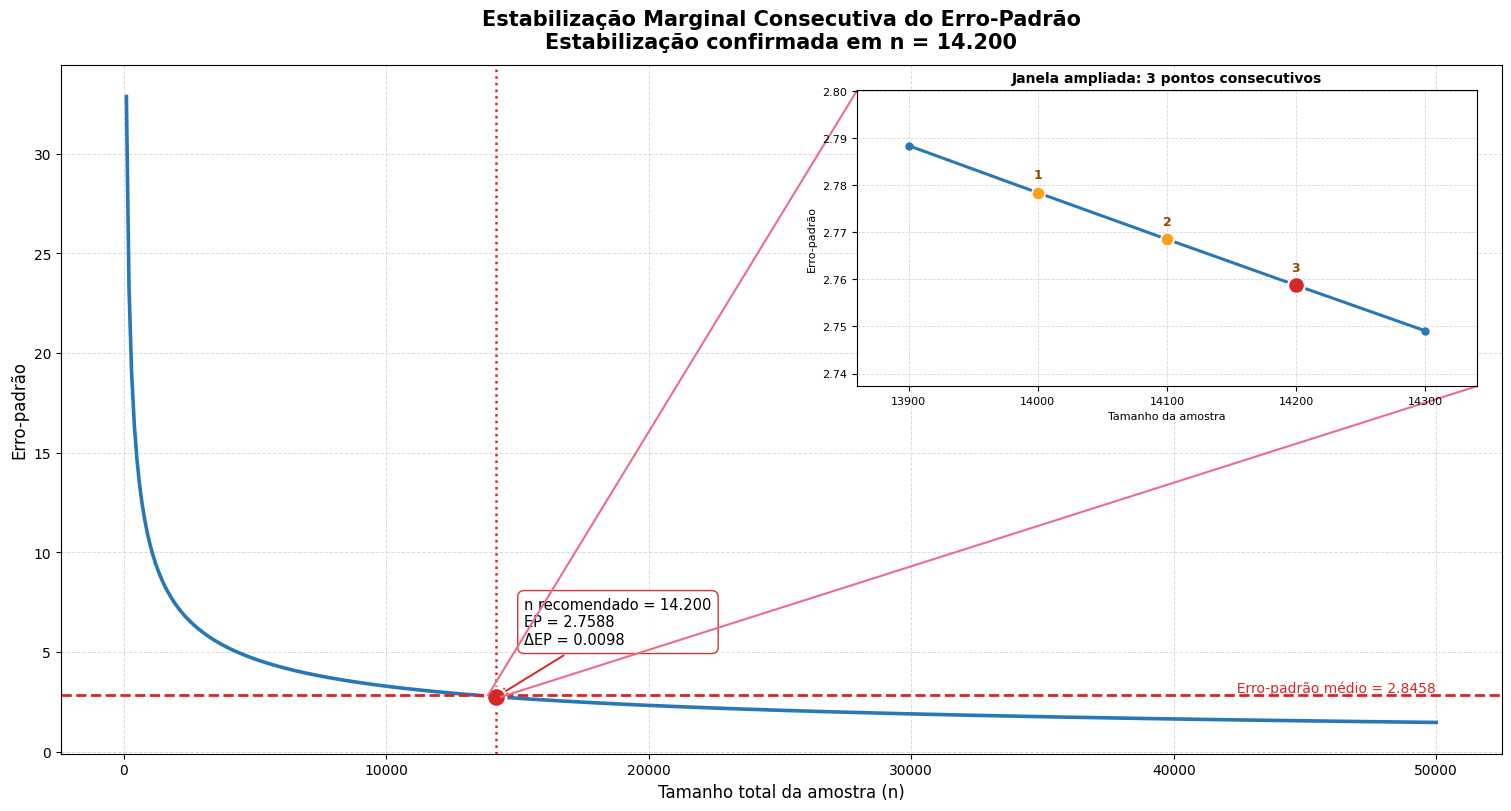

ESSENTIAL: n ideal = 14200, erro-padrão = R$ 2.7588


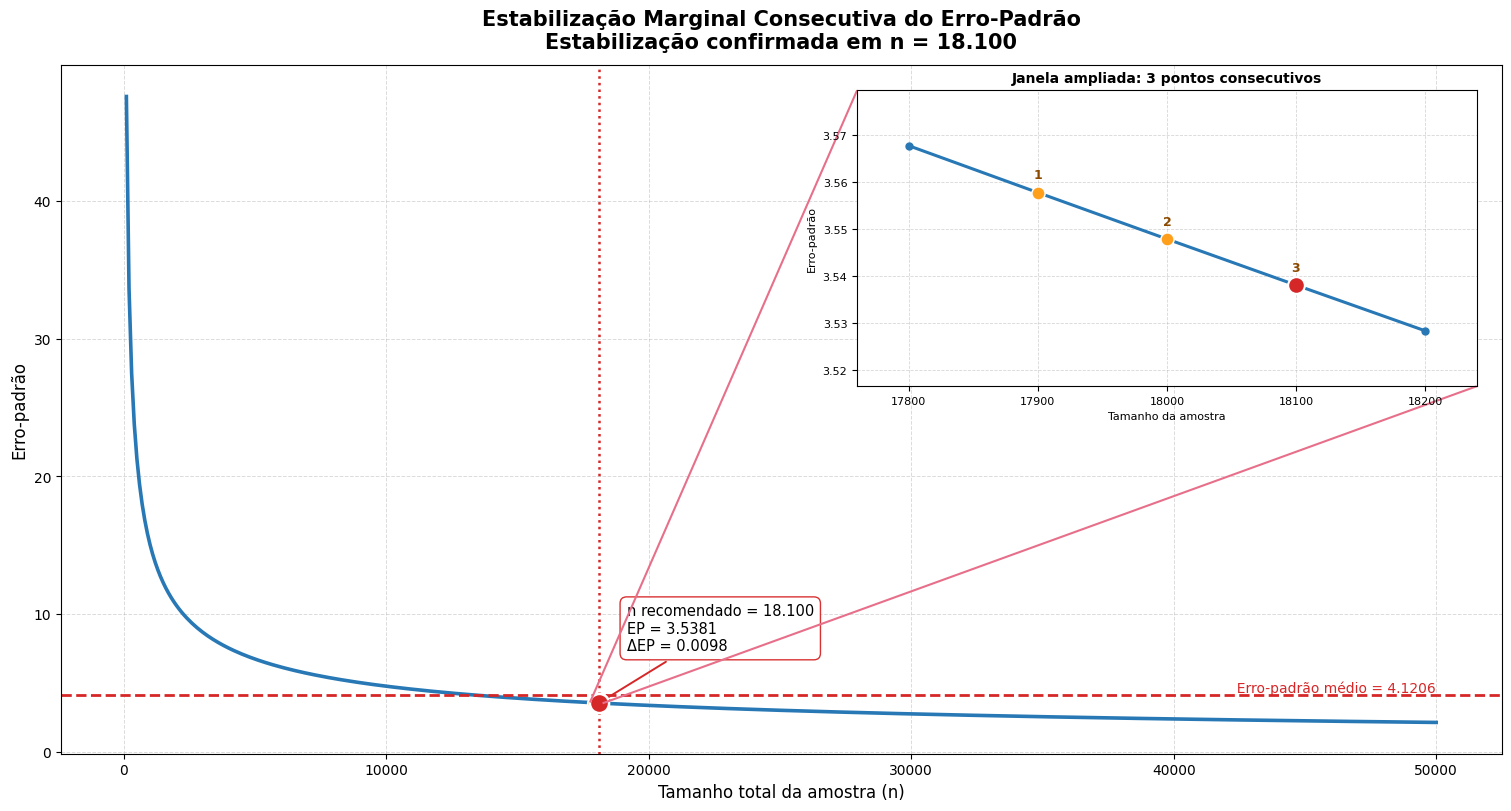

VIP: n ideal = 18100, erro-padrão = R$ 3.5381


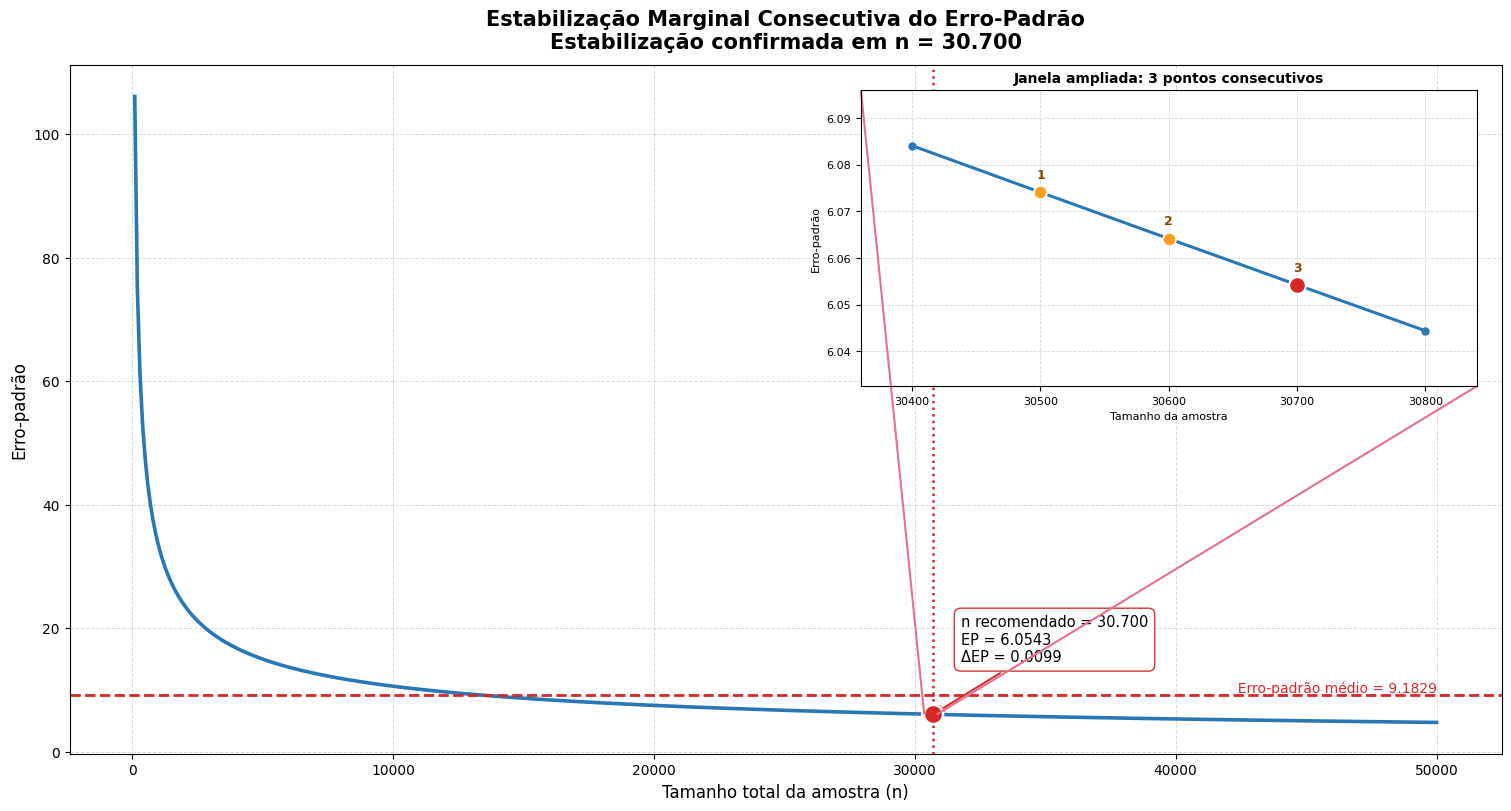

PRIME: n ideal = 30700, erro-padrão = R$ 6.0543


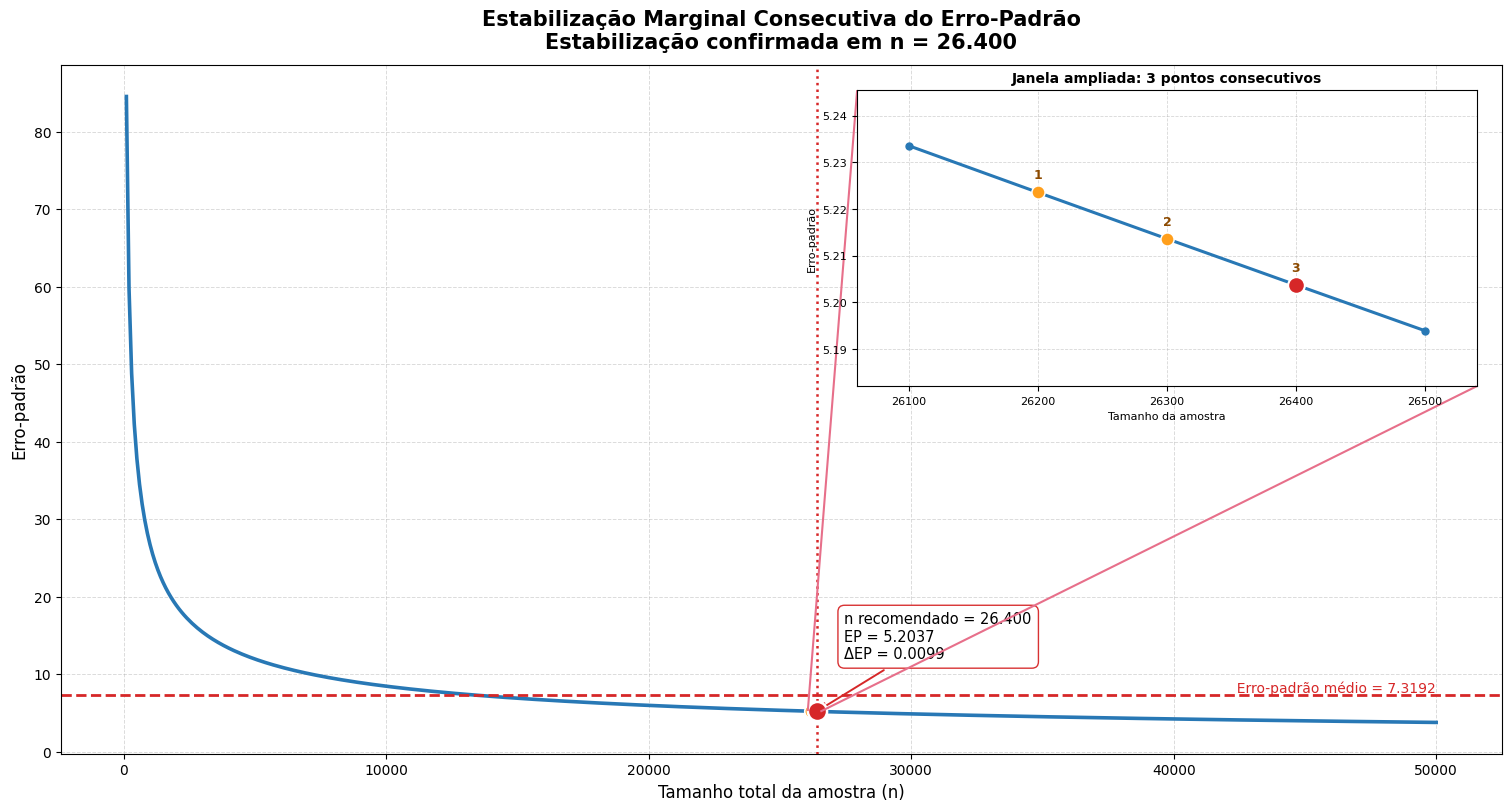

GERAL: n ideal = 26400, erro-padrão = R$ 5.2037

PASSO 2: Procedimento teórico-empírico (optimal_stratified_sample_size)


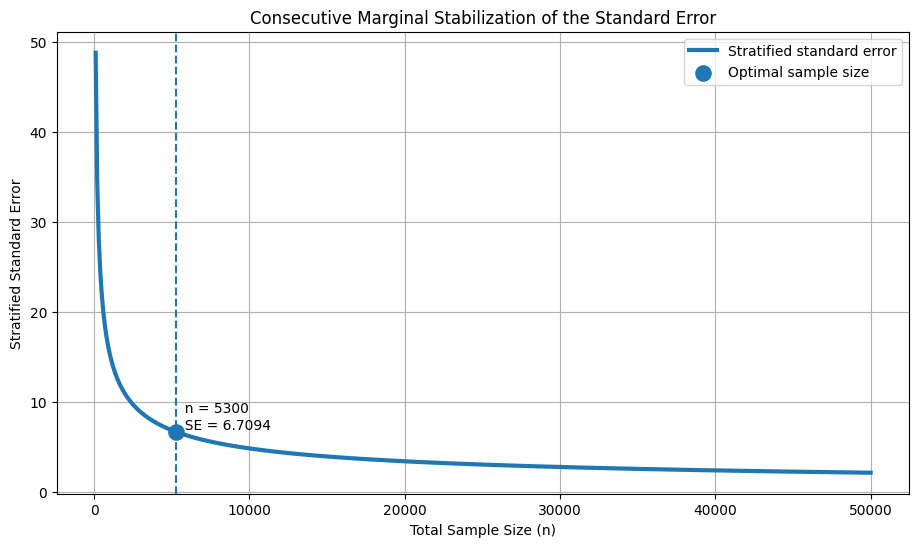

     Stratum  Population Weight (Wh)  Std. Deviation (Sh)  \
0  ESSENTIAL                0.595240           328.743630   
1      PRIME                0.171178          1060.791829   
2        VIP                0.233582           476.004599   

   Neyman Weight (Wh x Sh)  Allocated Sample (nh)  Allocated Sample (%)  
0               195.681417                   2123              0.400642  
1               181.583883                   1970              0.371768  
2               111.186174                   1206              0.227590  

n ideal (estratificado) = 5300

PASSO 3: Busca do tamanho ideal por bootstrap (margem de IC <= 1%)
ESSENTIAL: menor n com margem <= 1% = 25,000
VIP: menor n com margem <= 1% = 10,000
PRIME: menor n com margem <= 1% = 15,000
GERAL: menor n com margem <= 1% = 40,000

Tamanho ideal da amostra adotado (maior exigência entre os grupos): 40,000

PASSO 4: Validação final no n adotado (n = 40,000)
ESSENTIAL : média real = R$    415.56 | média estimada = R$    41

{'estratificado': (     Stratum  Population Weight (Wh)  Std. Deviation (Sh)  \
  0  ESSENTIAL                0.595240           328.743630   
  1      PRIME                0.171178          1060.791829   
  2        VIP                0.233582           476.004599   
  
     Neyman Weight (Wh x Sh)  Allocated Sample (nh)  Allocated Sample (%)  
  0               195.681417                   2123              0.400642  
  1               181.583883                   1970              0.371768  
  2               111.186174                   1206              0.227590  ,
  {'optimal_n': 5300,
   'optimal_standard_error': 6.709396995239152,
   'sample_sizes': array([  100,   200,   300,   400,   500,   600,   700,   800,   900,
           1000,  1100,  1200,  1300,  1400,  1500,  1600,  1700,  1800,
           1900,  2000,  2100,  2200,  2300,  2400,  2500,  2600,  2700,
           2800,  2900,  3000,  3100,  3200,  3300,  3400,  3500,  3600,
           3700,  3800,  3900,  4000,  4100, 

In [94]:
AtividadeA1_1()

In [ ]:
help(AtividadeA1_1)

###Atividade A1.2: Analisar os outliers

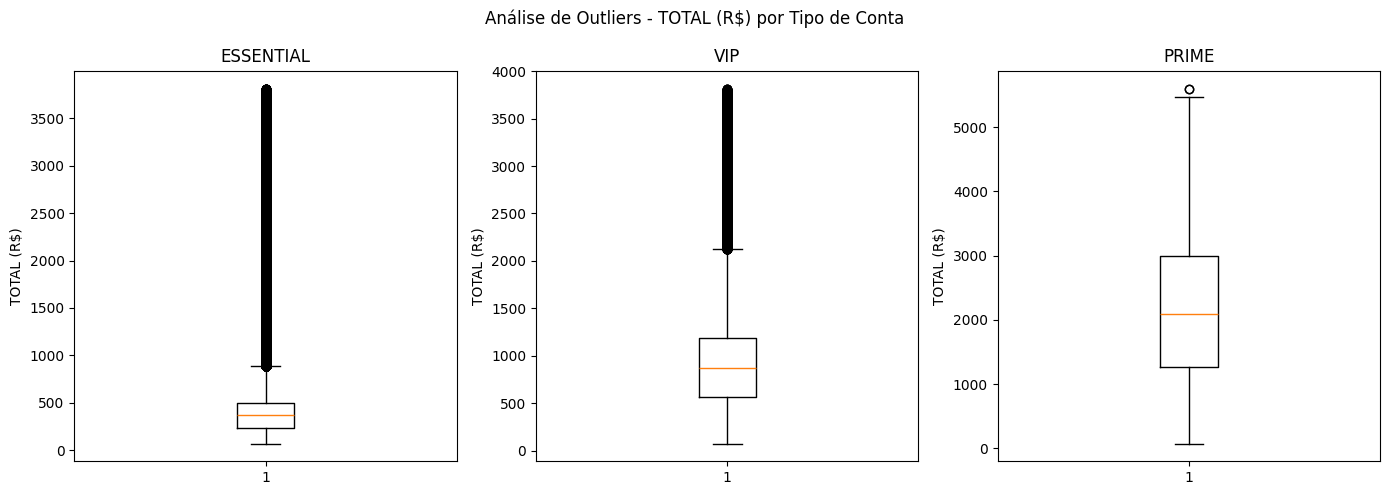

     Tipo      Q1      Q3     IQR  Limite inferior  Limite superior  Qtd outliers  % outliers
ESSENTIAL  239.16  498.55  259.39                0           887.64         24371        3.66
      VIP  561.89 1187.58  625.69                0          2126.12          7087        2.71
    PRIME 1267.32 2990.98 1723.66                0          5576.48             2        0.00

DECISÃO: Outliers MANTIDOS na base.
Justificativa: representam gastos legítimos de clientes de alto
consumo, não erros de coleta ou digitação. Removê-los distorceria
o comportamento real de consumo de cada tipo de conta.


,Tipo,Q1,Q3,IQR,Limite inferior,Limite superior,Qtd outliers,% outliers
0,ESSENTIAL,239.16,498.55,259.39,0,887.64,24371,3.66
1,VIP,561.89,1187.58,625.69,0,2126.12,7087,2.71
2,PRIME,1267.32,2990.98,1723.66,0,5576.48,2,0.00


In [99]:
AtividadeA1_2()

###Atividade A1.3: Testes de Hipóteses ([Link](https://colab.research.google.com/drive/1_YGamH-qOWSNaCKG5kVlLiZPuXv5lT34?usp=sharing))

#### A1.3.1: Teste de Normalidade

Nesta ETAPA, você deve fazer o **TESTE DE HIPÓTESE DE NORMALIDADE: Anderson-Darling' Test (AD test)** sobre:

*   SAMPLE 1: ESSENTIAL (n = 40000)
*   SAMPLE 2: PRIME (n = 40000)

In [106]:
AtividadeA1_3_1()

SAMPLE 1 (ESSENTIAL) - DISTRIBUIÇÃO AMOSTRAL: stat = 3556.771
  Intervalo de Confiança (15.0%): Provavelmente NÃO Gaussiana.
  Intervalo de Confiança (10.0%): Provavelmente NÃO Gaussiana.
  Intervalo de Confiança (5.0%): Provavelmente NÃO Gaussiana.
  Intervalo de Confiança (2.5%): Provavelmente NÃO Gaussiana.
  Intervalo de Confiança (1.0%): Provavelmente NÃO Gaussiana.

SAMPLE 2 (PRIME) - DISTRIBUIÇÃO AMOSTRAL: stat = 253.174
  Intervalo de Confiança (15.0%): Provavelmente NÃO Gaussiana.
  Intervalo de Confiança (10.0%): Provavelmente NÃO Gaussiana.
  Intervalo de Confiança (5.0%): Provavelmente NÃO Gaussiana.
  Intervalo de Confiança (2.5%): Provavelmente NÃO Gaussiana.
  Intervalo de Confiança (1.0%): Provavelmente NÃO Gaussiana.



**Conclusão**

ESSENTIAL e PRIME foram escolhidos por representarem os extremos de gasto e variabilidade do clube (A1.1), tornando a comparação estatística mais informativa que entre grupos intermediários.

Nenhuma das duas amostras segue distribuição normal, em nenhum dos níveis de confiança testados (15% a 1%).

#### A1.3.2: Teste de Independência

Nesta ETAPA, você deve fazer o **TESTE DE ANOVA (+ Gráfico Bootstrap) sobre Testes de Independência: p_value** sobre:


Pearson: stat = -0.0038, p-valor = 0.4483
Spearman: stat = 0.0015, p-valor = 0.7666
Kendall: stat = 0.0010, p-valor = 0.7671


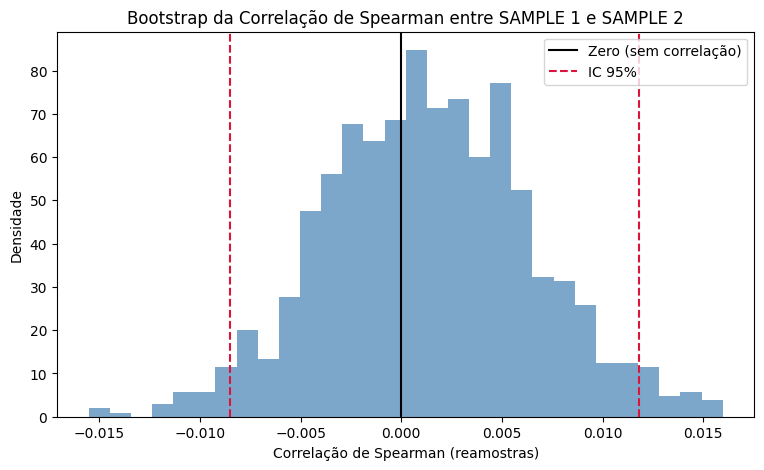


IC 95% (bootstrap) da correlação de Spearman: ConfidenceInterval(low=np.float64(-0.008500684963637482), high=np.float64(0.011812939497938322))


({'Pearson': PearsonRResult(statistic=np.float64(-0.003790998198850531), pvalue=np.float64(0.4483440287979301)),
  'Spearman': SignificanceResult(statistic=np.float64(0.0014841188410606426), pvalue=np.float64(0.7666080157448258)),
  'Kendall': SignificanceResult(statistic=np.float64(0.0009874997113243746), pvalue=np.float64(0.767052285134972))},
 BootstrapResult(confidence_interval=ConfidenceInterval(low=np.float64(-0.008500684963637482), high=np.float64(0.011812939497938322)), bootstrap_distribution=array([-9.14622869e-03, -1.92296334e-03,  8.52798903e-03,  2.41052275e-03,
        -1.10799895e-03,  5.42005717e-03, -1.74416981e-03, -3.86579718e-03,
         2.96250392e-03, -5.85208834e-04,  3.33217766e-03, -4.61620956e-04,
         2.45797929e-03,  3.68018486e-03,  6.34413186e-03, -8.31675111e-04,
        -4.67712470e-03,  2.98272393e-03,  7.09411420e-04, -3.10299701e-03,
         3.00380850e-04, -3.96257961e-03, -6.70451405e-04, -3.22387062e-03,
         4.36084493e-03,  1.16984231e-0

In [119]:
AtividadeA1_3_2()

### **Conclusão**

- **SAMPLE 1 e SAMPLE 2 são independentes**: os três testes de correlação (Pearson, Spearman, Kendall) retornaram p-valor >> 0,05, não havendo evidência de relação estatística entre as amostras.

- **BEST FIT**: Spearman (ou Kendall), pois não exigem normalidade dos dados — diferente de Pearson, que assume relação linear e distribuição aproximadamente normal, violada conforme A1.3.1.

#### A1.3.3: Teste de Distribuição

Nesta ETAPA, você deve fazer o **TESTE DE ANOVA (+ Gráfico Bootstrap) sobre Teste de Mesma Distribuição: p_value**


ttest_ind (paramétrico): stat = -313.8190, p-valor = 0.000000
f_oneway (paramétrico): stat = 98482.3598, p-valor = 0.000000
mannwhitneyu (não-paramétrico): stat = 61990797.0000, p-valor = 0.000000
kruskal (não-paramétrico): stat = 51061.0102, p-valor = 0.000000

--- Gráfico Bootstrap: SAMPLE 1 (ESSENTIAL) ---


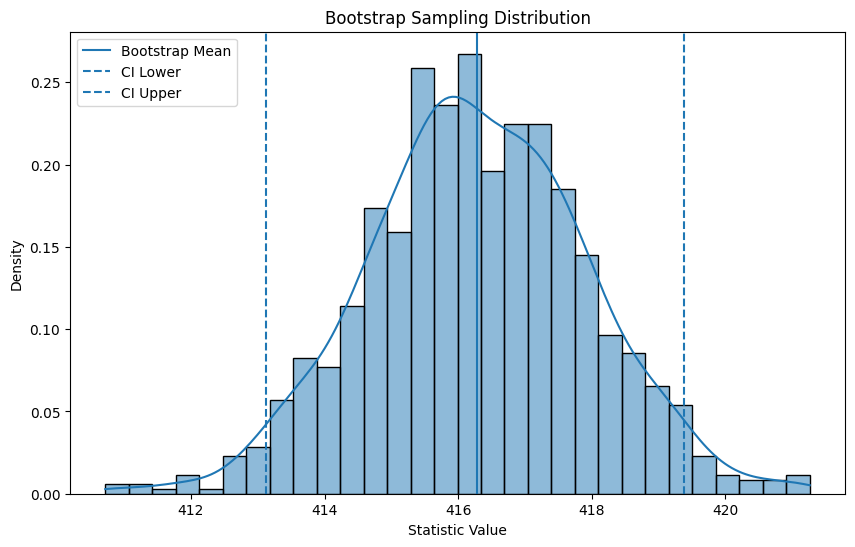

CONFIDENCE INTERVAL
LOW  : 413.1207
HIGH : 419.3846
SE   : 1.6379

--- Gráfico Bootstrap: SAMPLE 2 (PRIME) ---


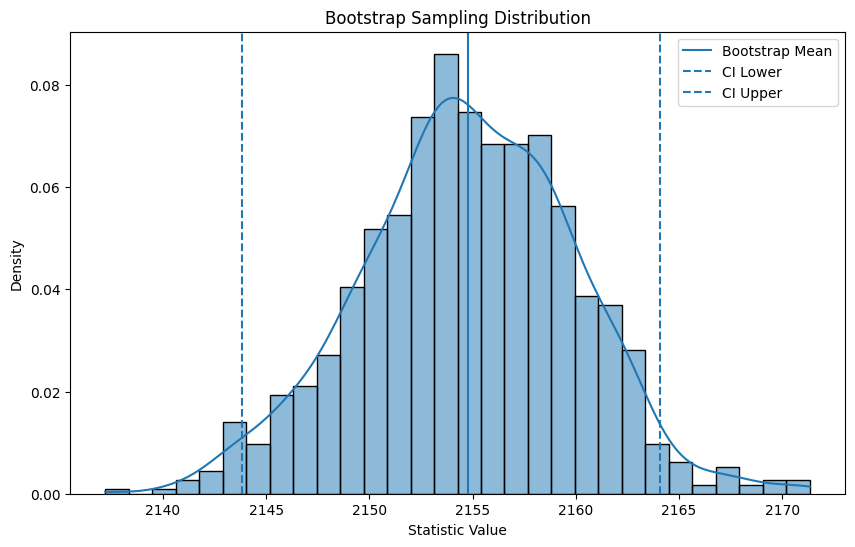

CONFIDENCE INTERVAL
LOW  : 2143.8302
HIGH : 2164.0817
SE   : 5.1532


({'ttest_ind (paramétrico)': TtestResult(statistic=np.float64(-313.818992169815), pvalue=np.float64(0.0), df=np.float64(79998.0)),
  'f_oneway (paramétrico)': F_onewayResult(statistic=np.float64(98482.3598464782), pvalue=np.float64(0.0)),
  'mannwhitneyu (não-paramétrico)': MannwhitneyuResult(statistic=np.float64(61990797.0), pvalue=np.float64(0.0)),
  'kruskal (não-paramétrico)': KruskalResult(statistic=np.float64(51061.01023097901), pvalue=np.float64(0.0))},
 (BootstrapResult(confidence_interval=ConfidenceInterval(low=np.float64(413.12068489999996), high=np.float64(419.38458086249994)), bootstrap_distribution=array([416.9094245 , 419.37449425, 417.257711  , 416.581837  ,
         418.8134895 , 415.51385025, 413.98778625, 418.9747415 ,
         415.5889505 , 416.31478625, 418.1550525 , 415.95664725,
         417.061755  , 417.84065575, 416.0757525 , 413.47087075,
         416.27125425, 415.0003835 , 414.82938425, 418.36398875,
         414.88888525, 415.04520125, 414.868058  , 414.743

In [123]:
AtividadeA1_3_3()

## **Conclusão**

- **SAMPLE 1 e SAMPLE 2 não têm a mesma distribuição**: todos os 4 testes (paramétricos e não-paramétricos) rejeitam essa hipótese com **p-valor ≈ 0**.

- **BEST FIT**: Kruskal-Wallis (não-paramétrico), consistente com a não-normalidade confirmada na A1.3.1. Resultado concorda com o esperado, já que ESSENTIAL e PRIME representam perfis de gasto opostos por desenho do negócio.

#### A1.3.4: Teste das Médias Amostrais

Nesta ETAPA, você deve fazer o **TESTE DE ANOVA (+ Gráfico Bootstrap) sobre Teste das Médias Amostrais: p_value** sobre:

*   SAMPLE 1 e SAMPLE 2
*   RESPONDER: Qual o BEST FIT ?

ttest_ind: stat = -313.8190, p-valor = 0.000000
Média SAMPLE 1 (ESSENTIAL): R$ 416.21
Média SAMPLE 2 (PRIME): R$ 2,154.59

--- Gráfico Bootstrap: SAMPLE 1 (ESSENTIAL) ---


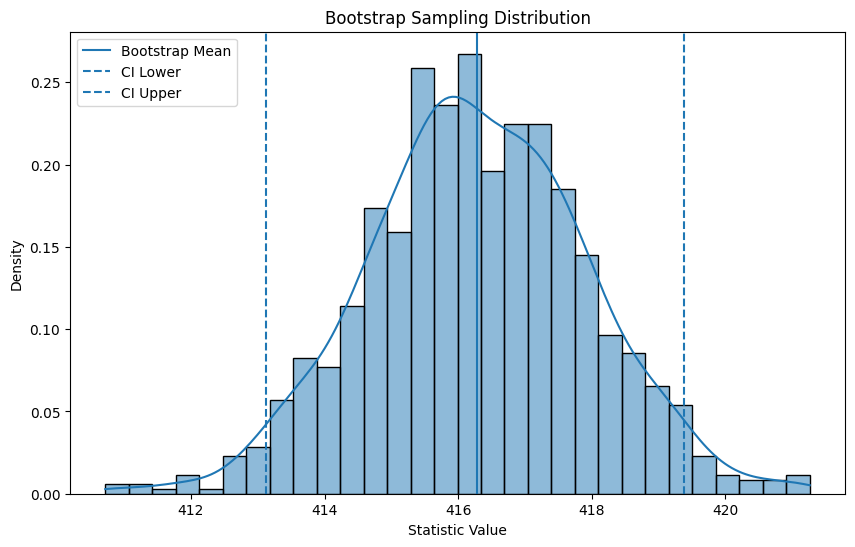

CONFIDENCE INTERVAL
LOW  : 413.1207
HIGH : 419.3846
SE   : 1.6379

--- Gráfico Bootstrap: SAMPLE 2 (PRIME) ---


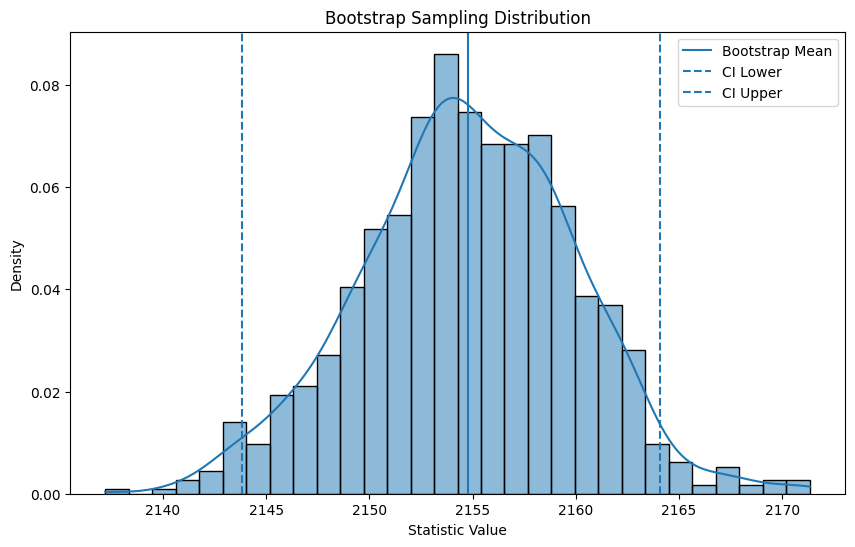

CONFIDENCE INTERVAL
LOW  : 2143.8302
HIGH : 2164.0817
SE   : 5.1532


(TtestResult(statistic=np.float64(-313.818992169815), pvalue=np.float64(0.0), df=np.float64(79998.0)),
 (BootstrapResult(confidence_interval=ConfidenceInterval(low=np.float64(413.12068489999996), high=np.float64(419.38458086249994)), bootstrap_distribution=array([416.9094245 , 419.37449425, 417.257711  , 416.581837  ,
         418.8134895 , 415.51385025, 413.98778625, 418.9747415 ,
         415.5889505 , 416.31478625, 418.1550525 , 415.95664725,
         417.061755  , 417.84065575, 416.0757525 , 413.47087075,
         416.27125425, 415.0003835 , 414.82938425, 418.36398875,
         414.88888525, 415.04520125, 414.868058  , 414.74301625,
         419.21207175, 415.2469325 , 415.48815125, 415.24811175,
         415.75756675, 416.1692205 , 417.82921825, 416.838075  ,
         417.37871025, 419.32963375, 416.1752295 , 415.534329  ,
         415.86610825, 417.2736925 , 414.94053775, 416.1799135 ,
         414.0731355 , 416.61551025, 414.2144065 , 415.953088  ,
         415.00542125, 414.827

In [125]:
AtividadeA1_3_4()

### **Conclusão**

- **SAMPLE 1 e SAMPLE 2 não têm as mesmas médias amostrais**: o ttest_ind rejeita a igualdade com p-valor ≈ 0 (stat = -313,82). Os IC 95% bootstrap de cada amostra (ESSENTIAL: `R$ 413,12` a `R$ 419,38`; PRIME: `R$ 2.143,83` a `R$ 2.164,08`) não se sobrepõem, confirmando visualmente a diferença.

- **Resultado esperado e coerente:** ESSENTIAL e PRIME são, por desenho do negócio, os extremos de gasto do clube — a diferença de média (`R$ 416` vs `R$ 2.155`) reflete exatamente esse perfil.

##Atividade A2 ([Link](https://colab.research.google.com/drive/1w-72bl_qBnGIR8y9zcGYNcpar9b2JdwA?usp=sharing)): Estatística descritiva

###Atividade A2.1: Analisar as variáveis Quantitativas

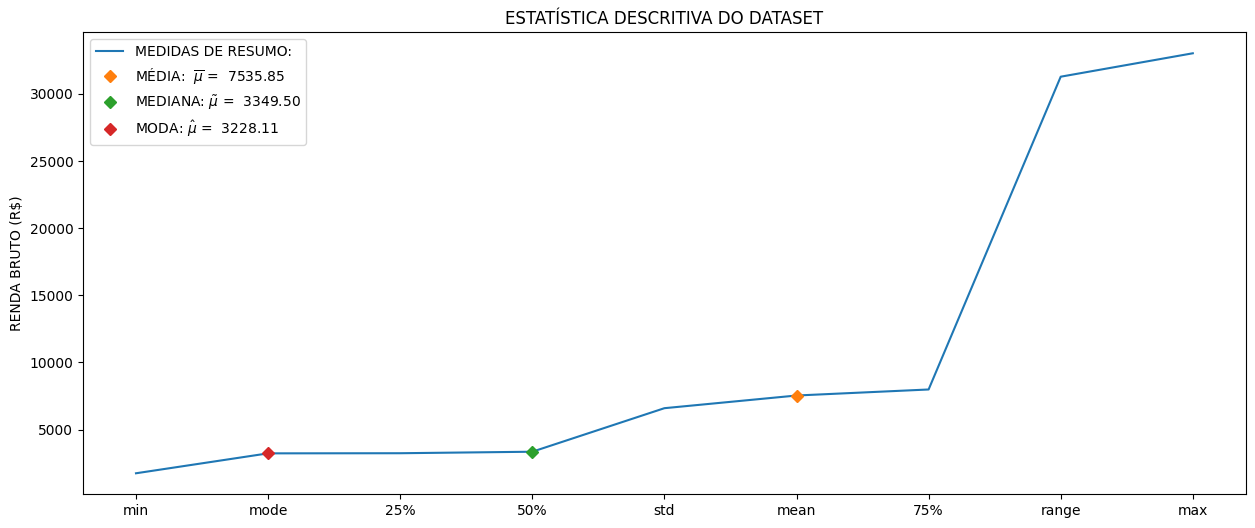

ESTATÍSTICA DESCRITIVA DO DATASET:
min       1744.17
mode      3228.11
25%       3237.52
50%       3349.50
std       6591.67
mean      7535.85
75%       7984.86
range    31279.79
max      33023.96
Name: RENDA BRUTO (R$), dtype: float64


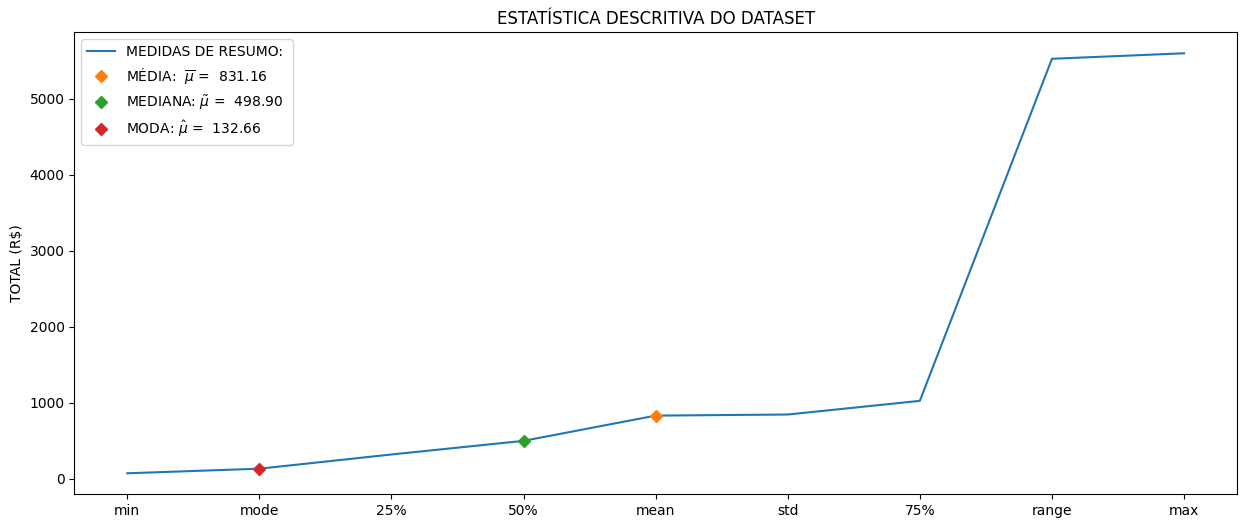

ESTATÍSTICA DESCRITIVA DO DATASET:
min        72.48
mode      132.66
25%       319.88
50%       498.90
mean      831.16
std       845.50
75%      1025.26
range    5525.32
max      5597.80
Name: TOTAL (R$), dtype: float64


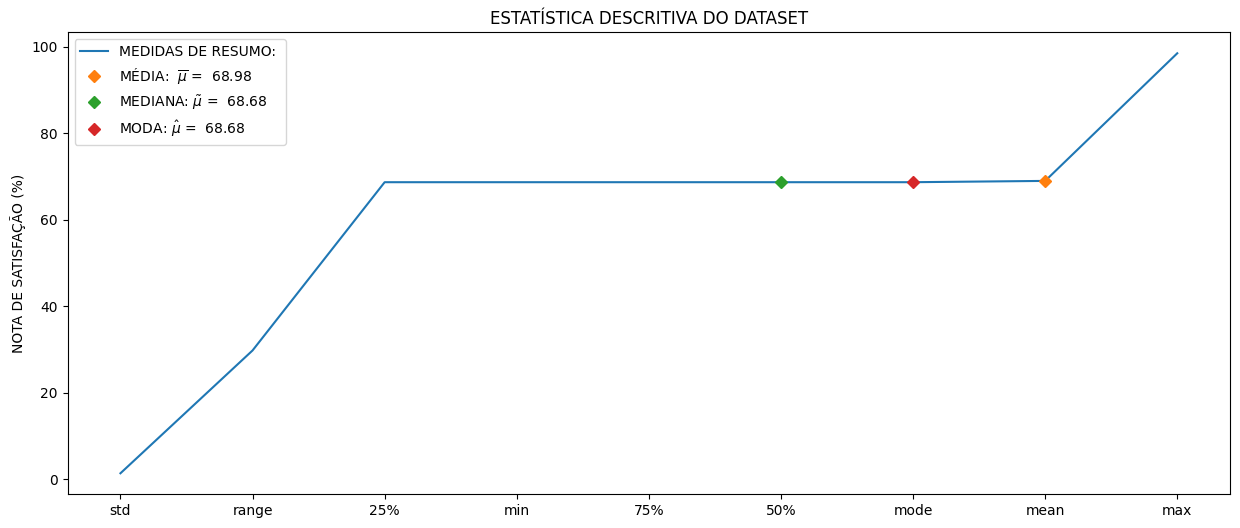

ESTATÍSTICA DESCRITIVA DO DATASET:
std       1.40
range    29.79
25%      68.68
min      68.68
75%      68.68
50%      68.68
mode     68.68
mean     68.98
max      98.48
Name: NOTA DE SATISFAÇÃO (%), dtype: float64
PERFIL QUÍMICO DO VINHO (consolidado):
       MEAN: alcohol  MEAN: malic_acid  MEAN: ash  MEAN: alcalinity_of_ash  \
25%            12.45              1.58       2.18                    17.25   
50%            13.00              2.34       2.37                    19.49   
75%            13.55              3.09       2.55                    21.74   
max            16.87              7.60       3.68                    35.15   
mean           13.00              2.34       2.37                    19.49   
min             8.93             -3.35       0.88                     4.03   
mode            8.93             -3.35       0.88                     4.03   
range           7.94             10.96       2.80                    31.11   
std             0.81              1.11      

,MEAN: alcohol,MEAN: malic_acid,MEAN: ash,MEAN: alcalinity_of_ash,MEAN: magnesium,MEAN: total_phenols,MEAN: flavanoids,MEAN: nonflavanoid_phenols,MEAN: proanthocyanins,MEAN: color_intensity,MEAN: hue,MEAN: od280/od315_of_diluted_wines,MEAN: proline
25%,12.45,1.58,2.18,17.25,90.12,1.87,1.36,0.28,1.21,3.50,0.80,2.13,535.56
50%,13.00,2.34,2.37,19.49,99.75,2.29,2.03,0.36,1.59,5.06,0.96,2.61,746.69
75%,13.55,3.09,2.55,21.74,109.36,2.71,2.70,0.45,1.98,6.62,1.11,3.09,958.52
max,16.87,7.60,3.68,35.15,170.05,5.45,6.93,1.04,4.25,16.61,2.09,5.95,2321.29
mean,13.00,2.34,2.37,19.49,99.74,2.29,2.03,0.36,1.59,5.06,0.96,2.61,746.99
min,8.93,-3.35,0.88,4.03,31.99,-1.23,-2.91,-0.25,-1.18,-5.91,-0.20,-0.90,-754.41
mode,8.93,-3.35,0.88,4.03,31.99,-1.23,-2.91,-0.25,-1.18,-5.91,-0.20,-0.90,-754.41
range,7.94,10.96,2.80,31.11,138.06,6.68,9.84,1.29,5.43,22.51,2.29,6.85,3075.71
std,0.81,1.11,0.27,3.33,14.24,0.62,0.99,0.12,0.57,2.31,0.23,0.71,313.81


In [134]:
AtividadeA2_1()

###Atividade A2.2: Analisar as variáveis Qualitativas

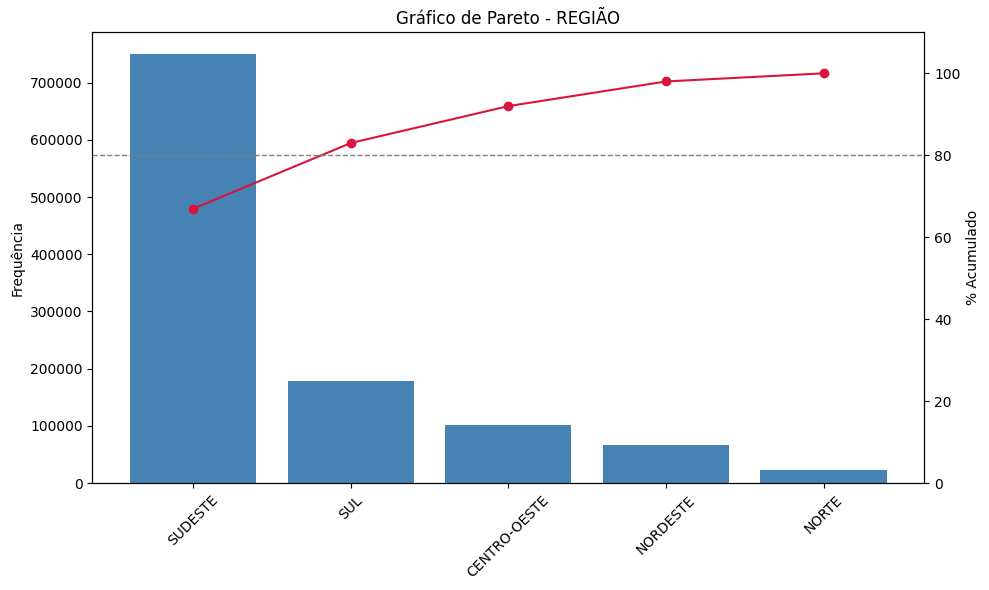

REGIÃO: 5 categorias; 2 delas já somam 80% do total.



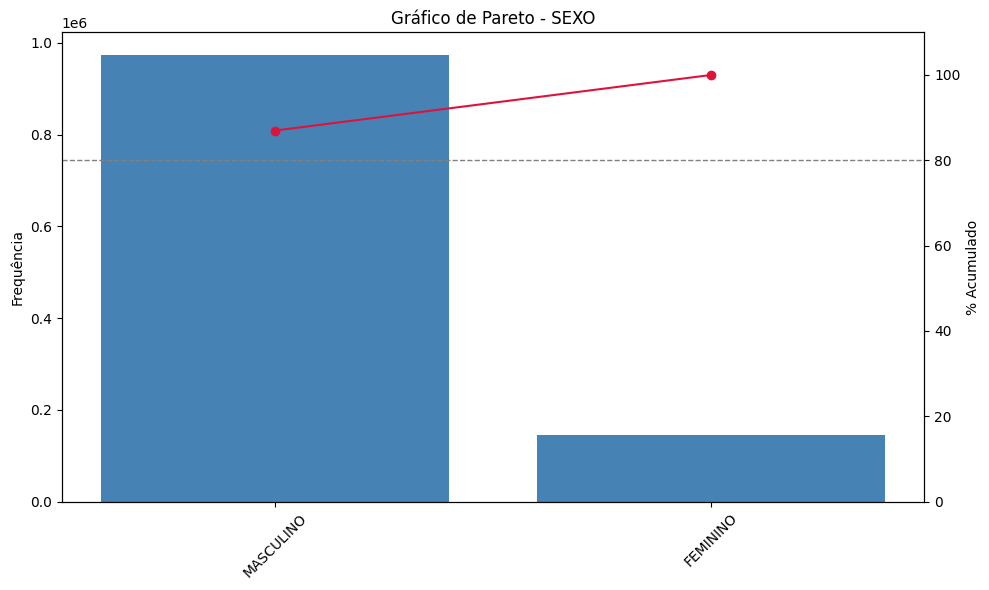

SEXO: 2 categorias; 1 delas já somam 80% do total.



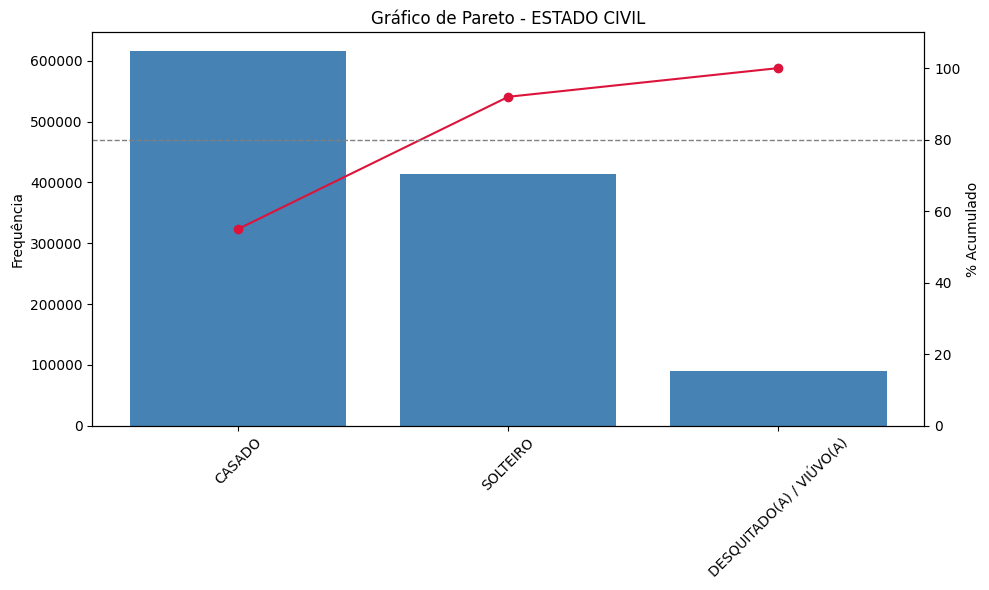

ESTADO CIVIL: 3 categorias; 2 delas já somam 80% do total.



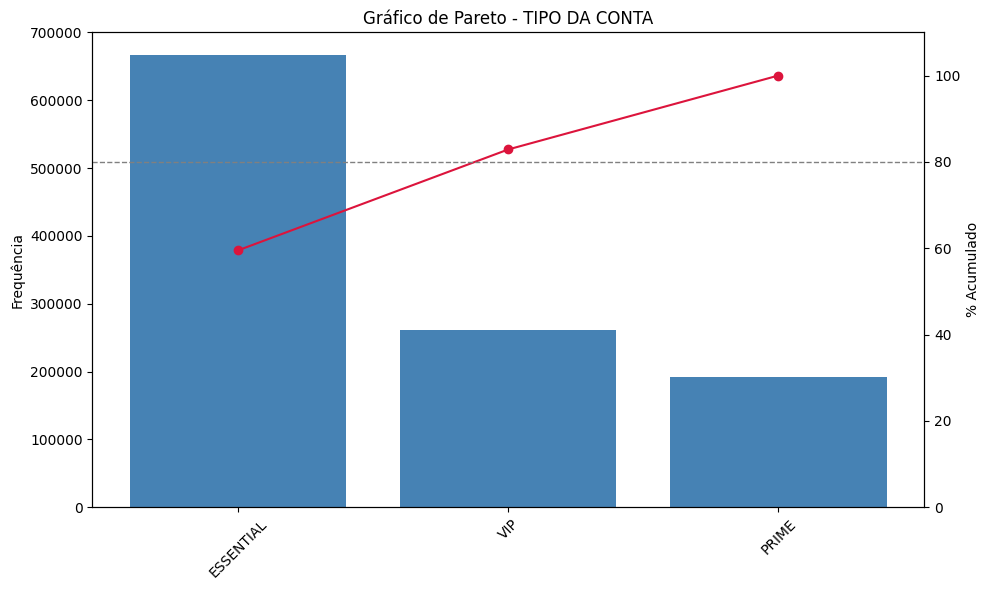

TIPO DA CONTA: 3 categorias; 2 delas já somam 80% do total.



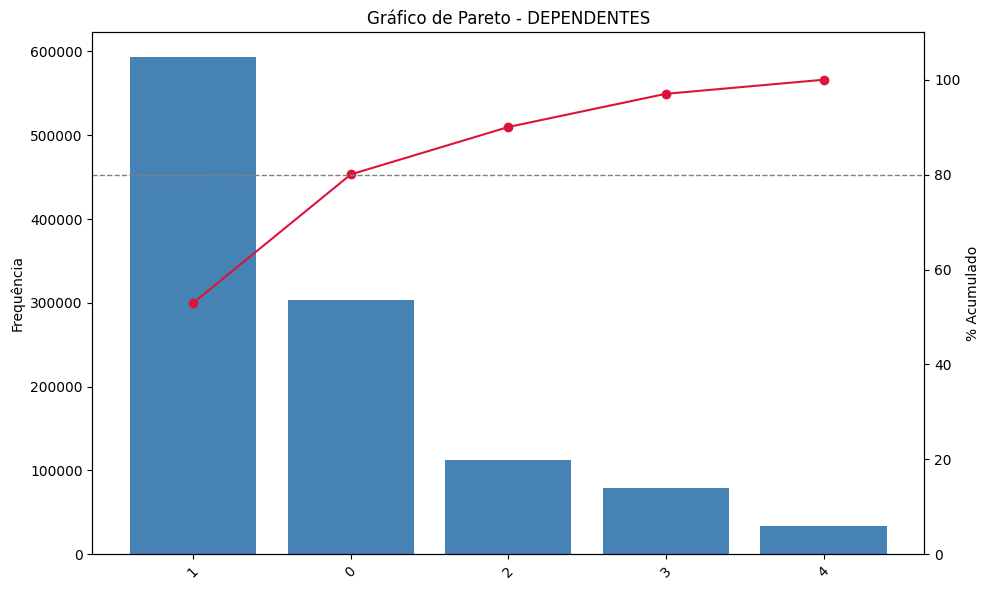

DEPENDENTES: 5 categorias; 2 delas já somam 80% do total.



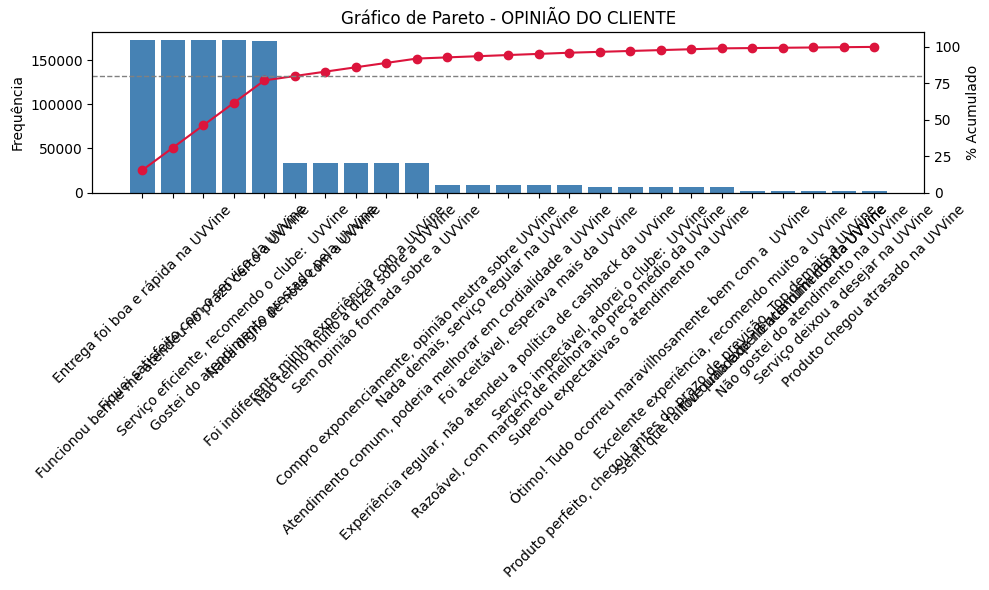

OPINIÃO DO CLIENTE: 25 categorias; 6 delas já somam 80% do total.



{'REGIÃO': (REGIÃO
  SUDESTE         750186
  SUL             179381
  CENTRO-OESTE    100870
  NORDESTE         67294
  NORTE            22269
  Name: count, dtype: int64,
  REGIÃO
  SUDESTE          66.980893
  SUL              82.997054
  CENTRO-OESTE     92.003304
  NORDESTE         98.011696
  NORTE           100.000000
  Name: count, dtype: float64),
 'SEXO': (SEXO
  MASCULINO    974185
  FEMININO     145815
  Name: count, dtype: int64,
  SEXO
  MASCULINO     86.980804
  FEMININO     100.000000
  Name: count, dtype: float64),
 'ESTADO CIVIL': (ESTADO CIVIL
  CASADO                      616145
  SOLTEIRO                    413995
  DESQUITADO(A) / VIÚVO(A)     89860
  Name: count, dtype: int64,
  ESTADO CIVIL
  CASADO                       55.012946
  SOLTEIRO                     91.976786
  DESQUITADO(A) / VIÚVO(A)    100.000000
  Name: count, dtype: float64),
 'TIPO DA CONTA': (TIPO DA CONTA
  ESSENTIAL    666669
  VIP          261612
  PRIME        191719
  Name: count, dtype: 

In [136]:
AtividadeA2_2()

##Atividade A3: Resultado da Pesquisa de Satisfação

Fazer o resultado da Pesquisa de satisfação do cliente em porcentagem (%):
* Geral
* Por Sexo

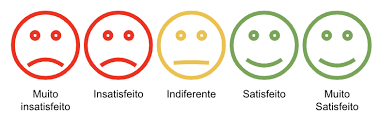

###Atividade A3.1: Discretizar a Variável Qualitativa (OPINIÃO DO CLIENTE)

Valores não mapeados (deveria ser 0): 0

NOTA 5 (Muito Satisfeito): 33,600 (3.0%)
NOTA 4 (Satisfeito): 862,400 (77.0%)
NOTA 3 (Indiferente): 168,000 (15.0%)
NOTA 2 (Insatisfeito): 44,800 (4.0%)
NOTA 1 (Muito Insatisfeito): 11,200 (1.0%)


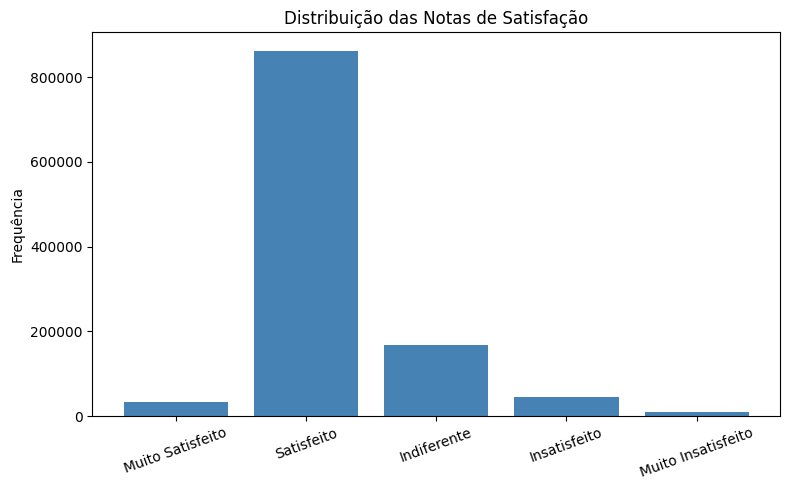

,NOTA
0,4
1,4
2,4
3,3
4,4
...,...
1119995,4
1119996,4
1119997,4
1119998,4


In [138]:
AtividadeA3_1()

###Atividade A3.2: Análise Bootstrap do resultado da Pesquisa de Satisfação

Média amostral da NOTA: 3.7696


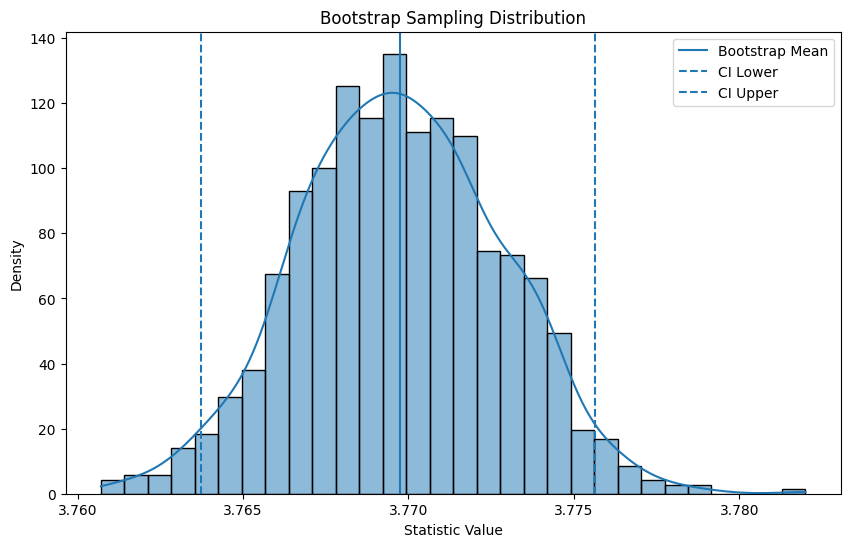

CONFIDENCE INTERVAL
LOW  : 3.7637
HIGH : 3.7757
SE   : 0.0031

Erro-Padrão (bootstrap): 0.0031
IC 95%: [3.7637 ; 3.7757]


(605510     4
 969981     4
 912275     4
 1061009    4
 43855      4
           ..
 143678     1
 946988     4
 177062     3
 1013525    3
 995174     2
 Name: NOTA, Length: 40000, dtype: int64,
 BootstrapResult(confidence_interval=ConfidenceInterval(low=np.float64(3.76372375), high=np.float64(3.77565)), bootstrap_distribution=array([3.774825, 3.7671  , 3.772125, 3.7682  , 3.7647  , 3.769975,
        3.768975, 3.76695 , 3.7708  , 3.772475, 3.7669  , 3.76835 ,
        3.768925, 3.773575, 3.7674  , 3.771825, 3.7644  , 3.774525,
        3.770225, 3.770875, 3.765825, 3.7695  , 3.7669  , 3.76625 ,
        3.771025, 3.76705 , 3.768775, 3.76695 , 3.771825, 3.774375,
        3.76435 , 3.774075, 3.77355 , 3.771125, 3.764425, 3.77845 ,
        3.764525, 3.7685  , 3.770775, 3.7688  , 3.763625, 3.77045 ,
        3.768275, 3.76575 , 3.769275, 3.7676  , 3.775925, 3.765825,
        3.766075, 3.77065 , 3.76735 , 3.771325, 3.765825, 3.76345 ,
        3.77035 , 3.771925, 3.76885 , 3.773225, 3.771225, 3

In [140]:
AtividadeA3_2()

###Atividade A3.3: Resultado Final da Pesquisa de Satisfação

RESULTADO GERAL (%):
NOTA
5     3.0
4    77.0
3    15.0
2     4.0
1     1.0
Name: proportion, dtype: float64

RESULTADO POR SEXO (%):
NOTA          5      4      3     2     1
SEXO                                     
FEMININO   3.01  77.03  14.99  3.95  1.02
MASCULINO  3.00  76.99  15.00  4.01  1.00


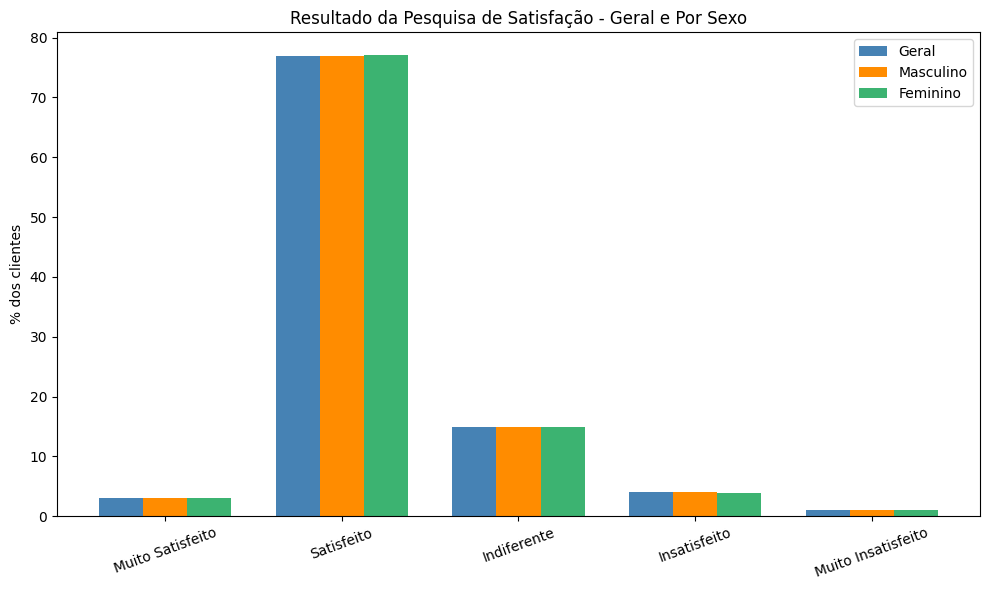

(NOTA
 5     3.0
 4    77.0
 3    15.0
 2     4.0
 1     1.0
 Name: proportion, dtype: float64,
 NOTA              5          4          3         2         1
 SEXO                                                         
 FEMININO   3.005864  77.033913  14.990913  3.948839  1.020471
 MASCULINO  2.999122  76.994924  15.001360  4.007658  0.996936)

In [142]:
AtividadeA3_3()

### **Conclusão:**

77% dos clientes estão satisfeitos, 3% muito satisfeitos, 15% indiferentes, e apenas 5% insatisfeitos ou muito insatisfeitos (somados).
O resultado é praticamente idêntico entre homens e mulheres (diferenças menores que 1 ponto percentual em cada nota) — o sexo do cliente não influencia a satisfação nessa base.
A nota média de satisfação, validada por bootstrap, é de 3,77 (IC 95%: 3,76–3,78), numa escala de 1 a 5.

# RELATÓRIO FINAL - PARTE 1

### **RELATÓRIO FINAL — PARTE 1**

***Resposta à pergunta central: Qual é o Tamanho Ideal da Amostra?***

Testamos dois procedimentos pedidos no roteiro (empírico e teórico-empírico), que divergiram fortemente entre si — o teórico-empírico (Neyman, com threshold percentual) convergiu sempre perto do mesmo valor (~5.300), independentemente da variabilidade real dos dados, uma limitação matemática do próprio critério. Por isso, adotamos uma validação mais rigorosa e defensável: uma busca por bootstrap real, que encontrou o menor tamanho de amostra que garante margem de erro do Intervalo de Confiança de 95% ≤ 1% em cada grupo (**VIP: 10 mil; PRIME: 15 mil; ESSENTIAL: 25 mil; GERAL, sem separar por grupo: 40 mil**).

Adotamos **n = 40.000** por grupo — o cenário mais exigente — validado por três propriedades estatísticas independentes: **viés praticamente nulo** (< 0,02% em todos os grupos), **margem de erro abaixo de 1%**, e **cobertura real do Intervalo de Confiança entre 95% e 98%** (checada por simulação direta contra a média verdadeira da população, algo possível aqui porque temos acesso à população inteira, não só a uma amostra).

**Síntese da Parte 1:**

- A base (1,12 milhão de notas fiscais) foi tratada (1 linha corrompida removida) e está pronta para uso.
- O tamanho de amostra de 40.000 por grupo é estatisticamente sólido e será a referência de trabalho daqui pra frente.
- ESSENTIAL e PRIME são, comprovadamente, perfis de consumo distintos em todos os aspectos testados (distribuição, média, variabilidade).
- Os dados não seguem distribuição normal — relevante para a escolha de modelos no Workflow 2 (Machine Learning).
- Há concentração estrutural forte em quase todas as variáveis qualitativas (região, sexo, tipo de conta) — classes desbalanceadas que podem exigir tratamento específico na modelagem.
- A satisfação do cliente é majoritariamente positiva (80% entre satisfeito e muito satisfeito) e não varia por sexo.
- O perfil químico do vinho contém ruído de simulação (valores impossíveis) — uma limitação conhecida e documentada da base, não um erro de análise.